# BTCUSDT v2, bare de volum: importanța feature-urilor pentru meta-labeling (CUSUM + triple barrier)

**Întrebarea.** Pe setul de bare de volum `volume_adapt60s` din `btcusdt_v2`: sunt feature-urile corecte, și care dintre ele aduc semnal real (nu zgomot) pentru **meta-labeling** cu **triple barrier**, când strategia primară tranzacționează **doar la evenimente CUSUM**?

**Rezultatul pe scurt.**

* **Datele trec verificările de integritate.** Au totuși trei capcane: ferestrele stricte de 1h/4h/24h lipsesc des, 75% din bare se închid în mijlocul unui sweep, iar cartea de ordine e degradată în martie–mai 2026.
* **Strategia primară** (momentum pe direcția evenimentului CUSUM, intrare după 1 s, bariere de ±0,5·σ₆₀, orizont 60 min) pierde **−1,07 bps brut pe tranzacție** (t = −5,2) pe 25.362 de evenimente.
* **Importanța feature-urilor** a fost calculată după metodologia cerută: RF cu `max_features=1`, MDI cu 0 → NaN, MDA și SFI pe Purged K-Fold cu embargo, PCA, Kendall τ ponderat, stivuire. **Niciun feature nu se distinge de zgomot.** Câte feature-uri trec pragul placebo pe fiecare metodă (MDI 5, MDA 7, SFI 0) e sub cât ar trece din întâmplare (~8 pe metodă). Niciun feature nu trece două metode, și niciunul nu trece în ambele jumătăți ale perioadei. τ ponderat este 0,04 (MDI) și −0,09 (MDA), nu 0,8. Rangurile MDA din cele patru blocuri de timp au corelația medie 0,02.
* **Testul în afara eșantionului.** Cele 15 feature-uri alese în perioada de descoperire sunt **mai slabe decât 15 feature-uri luate la întâmplare** pe perioada de validare (percentila 0–4).

Studiul este **explorator**. Toate lunile până în octombrie 2026 au fost deja folosite în notebook-urile anterioare. O confirmare cere date de după 2026-10-31.

**Reproducere.** Rulează din repository, cu env-ul conda `disertatie`. Durează ~35 min pe 16 nuclee și ~2 GB RAM. Variabile opționale:

* `FI_CACHE=<dir>` păstrează rezultatele grele între rulări;
* `FI_WORKERS` (implicit 16);
* `FI_QUICK=1` face un test rapid cu mai puțini arbori.

Rezultatele sunt deterministe (seed 20261109).

In [1]:
import os, re, json, sys, time, warnings, platform, resource, hashlib, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
import sklearn
from numba import njit
from scipy.stats import weightedtau, spearmanr, kendalltau
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import log_loss, roc_auc_score
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
T0 = time.time()
SEED = 20261109
WORKERS = int(os.environ.get("FI_WORKERS", "16"))
QUICK = os.environ.get("FI_QUICK", "0") == "1"           # smoke test: fewer trees and placebos
CACHE = Path(os.environ["FI_CACHE"]) if os.environ.get("FI_CACHE") else None

def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Rulează notebook-ul din interiorul repository-ului QuantForge.")
ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"
sys.path.insert(0, str(CHDDS))
from chdds.dataset import incident_rows, META_COLS, QUALITY_COLS
man = json.loads((DATA / "manifest.json").read_text())
SID = next(k for k, v in man["bar_sets"].items() if v["name"] == "volume_adapt60s")
FILES = sorted((DATA / SID).glob("*.parquet"))

def source_fingerprint():
    files = sorted((DATA / SID).glob("*.parquet")) + [DATA / "manifest.json"]
    return (len(files), sum(f.stat().st_size for f in files), max(f.stat().st_mtime_ns for f in files))
FINGERPRINT_START = source_fingerprint()

def cached(name, fn):
    """Heavy results are cached only when FI_CACHE is set; the key includes the run mode."""
    if CACHE is None:
        return fn()
    CACHE.mkdir(parents=True, exist_ok=True)
    p = CACHE / f"{name}{'_quick' if QUICK else ''}.pkl"
    if p.exists():
        return pickle.loads(p.read_bytes())
    out = fn(); p.write_bytes(pickle.dumps(out)); return out

C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", purple="#7a5bd0", red="#e34948", yellow="#d9a400")
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True, "lines.linewidth": 2.0, "legend.frameon": False, "legend.fontsize": 9})
pd.set_option("display.width", 230, "display.max_columns", 40, "display.max_rows", 200)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | dataset {DATA.name}/{SID}, creat {man['created_utc']} | "
      f"workers {WORKERS} | mod {'RAPID (test)' if QUICK else 'complet'}")

UTC = "UTC"
START = pd.Timestamp("2025-07-12", tz=UTC)          # after the 7-day warm-up of the adaptive threshold and the 24 h sigma window
DATA_END = pd.Timestamp("2026-11-01", tz=UTC)
DISC_END = pd.Timestamp("2026-03-01", tz=UTC)       # discovery period (selection) / validation period (out of sample)
CUSUM_K, BARRIER_K, HORIZON_MIN = 0.5, 1.0, 60      # h = 0.5 sigma_60m; barriers at +-1 h; vertical barrier at 60 min after the signal
LATENCY_S = 1.0                                      # entry at the close of the first bar at least 1 s after the signal (see the sweep check)
EMBARGO = pd.Timedelta(days=1)
N_SPLITS = 5
COSTS = [0, 4, 10]
N_TREES = 120 if QUICK else 500
N_TREES_SMALL = 60 if QUICK else 200
N_TREES_SFI = 40 if QUICK else 100
MIN_LEAF = 0.002                                     # min weighted fraction of samples per leaf (about 50 events)
MIN_LEAF_SFI = 0.01                                  # single-feature models: about 200 events per leaf, so a useless feature scores near zero

Python 3.11.13 | pandas 2.3.3 | scikit-learn 1.7.2 | dataset btcusdt_v2/volume_adapt60s-e794c55e50, creat 2026-11-05T20:01:10Z | workers 16 | mod complet


## 1. Verificarea datasetului

Fiecare lună e citită integral. Verific invarianții barei: timp monoton, `bar_id` unic, `eval_time ≤ decision_time`, L ≤ O, C ≤ H, VWAP în [L, H], |tfi_ratio| ≤ 1, identitatea tfi_ratio = tfi/V, spread ≥ 0, |qi_1| ≤ 1 și randamentul egal cu log(C/C₋₁). Apoi măsor, pentru fiecare dintre cele 666 de coloane, valorile lipsă, cele infinite și coloanele constante, lună cu lună.

In [2]:
bs = man["bar_sets"][SID]
print(f"Set de bare: {bs['name']} — volum adaptiv, ținta {bs['spec']['spec']['adaptive']['target_s']} s pe bară, prag recalibrat zilnic pe ultimele "
      f"{bs['spec']['spec']['adaptive']['lookback_days']} zile. Fișiere: {len(FILES)} luni, coloane: {len(bs['columns'])}.")
thr = pd.Series({k: v for k, v in bs["spec"]["schedule_info"].items() if v != "warmup"}, dtype=float)
print(f"Prag de volum: mediana {thr.median():.1f} BTC, min {thr.min():.1f}, max {thr.max():.1f} (zile de warm-up: {sum(v == 'warmup' for v in bs['spec']['schedule_info'].values())}).")

def quality_pass():
    rows, checks = [], []
    for f in FILES:
        t = pq.read_table(f).to_pandas()
        num = t.select_dtypes(include=[np.number])
        a = num.to_numpy(np.float64)
        rows.append(pd.DataFrame({"month": f.stem, "col": num.columns, "n": len(t), "null": np.isnan(a).sum(0), "inf": np.isinf(a).sum(0),
                                  "std": np.nanstd(np.where(np.isfinite(a), a, np.nan), 0)}))
        ok = (t["complete"] == 1)
        tn = t["decision_time_ns"].to_numpy()
        checks.append({
            "lună": f.stem, "bare": len(t), "complete %": 100 * ok.mean(), "feed complet %": 100 * (t["feed_complete"] == 1).mean(),
            "timp crescător": bool((np.diff(tn) >= 0).all()), "bar_id unic": t["bar_id"].is_unique,
            "eval ≤ decizie": bool((t["eval_time_ns"] <= t["decision_time_ns"]).all()),
            "L ≤ O,C ≤ H": bool(((t["bar_low"] <= t[["bar_open", "bar_close"]].min(1)) & (t[["bar_open", "bar_close"]].max(1) <= t["bar_high"])).all()),
            "VWAP în [L, H]": bool(((t["bar_vwap"] >= t["bar_low"] - 1e-6) & (t["bar_vwap"] <= t["bar_high"] + 1e-6)).all()),
            "|tfi_ratio| ≤ 1": bool((t["bar_tfi_ratio"].abs() <= 1 + 1e-9).all()),
            "tfi_ratio = tfi/V": float(np.nanmax(np.abs(t["bar_tfi_ratio"] - t["bar_tfi_btc"] / t["bar_volume_btc"]))) < 1e-9,
            "spread ≥ 0": bool((t["spread_bps"].dropna() >= 0).all()),
            "|qi_1| ≤ 1": bool((t["qi_1"].dropna().abs() <= 1 + 1e-9).all()),
            "ret = log(C/C₋₁)": float(np.nanmax(np.abs(t["bar_return_log"].to_numpy()[1:] - np.log(t["bar_close"].to_numpy()[1:] / t["bar_close"].to_numpy()[:-1])))) < 1e-9,
            "durata mediană (s)": t["bar_duration_s"].median(), "book valid %": 100 * t["book_state"].isin([0, 9]).mean(),
        })
        del t, num, a
    return pd.concat(rows, ignore_index=True), pd.DataFrame(checks).set_index("lună")
QSTAT, CHECKS = cached("quality", quality_pass)
display(CHECKS.round(2))

Set de bare: volume_adapt60s — volum adaptiv, ținta 60 s pe bară, prag recalibrat zilnic pe ultimele 7 zile. Fișiere: 16 luni, coloane: 666.
Prag de volum: mediana 48.1 BTC, min 27.3, max 128.6 (zile de warm-up: 7).


,bare,complete %,feed complet %,timp crescător,bar_id unic,eval ≤ decizie,"L ≤ O,C ≤ H","VWAP în [L, H]",|tfi_ratio| ≤ 1,tfi_ratio = tfi/V,spread ≥ 0,|qi_1| ≤ 1,ret = log(C/C₋₁),durata mediană (s),book valid %
lună,,,,,,,,,,,,,,,
2025-07,74263,99.91,99.91,True,True,True,True,True,True,True,True,True,True,16.40,99.47
2025-08,83884,99.88,99.88,True,True,True,True,True,True,True,True,True,True,17.36,97.34
2025-09,81380,99.84,99.84,True,True,True,True,True,True,True,True,True,True,17.33,98.06
2025-10,86602,99.35,99.35,True,True,True,True,True,True,True,True,True,True,17.17,95.24
2025-11,74810,99.77,99.77,True,True,True,True,True,True,True,True,True,True,19.41,97.25
2025-12,94634,99.84,99.84,True,True,True,True,True,True,True,True,True,True,12.38,98.87
2026-01,106068,99.84,99.84,True,True,True,True,True,True,True,True,True,True,10.81,97.71
2026-02,84294,99.83,99.83,True,True,True,True,True,True,True,True,True,True,14.06,99.46
2026-03,80431,99.57,99.57,True,True,True,True,True,True,True,True,True,True,18.26,91.54


666 coloane numerice. Valori infinite: 0. Coloane constante în cel puțin o lună: 16 (last_trade_age_ms, tw_state_24h, rv_n_returns_5s_grid100ms, rv_n_returns_30s_grid100ms, rv_n_returns_30s_grid1s, rv_n_returns_2m_grid1s, rv_n_returns_15m_grid1s, rv_n_returns_1h_grid1s, ...).
Coloane cu > 50% lipsă pe tot setul: 17; > 10%: 148; ≤ 1%: 153.


,lipsă %,luna cea mai proastă %,luna
col,,,
rv_asym_trade_24h_grid1m,87.2,100.0,2026-03
rv_pos_trade_24h_grid1m,87.2,100.0,2026-03
rv_n_returns_24h_grid1m,87.2,100.0,2026-03
bv_trade_24h_grid1m,87.2,100.0,2026-03
rv_trade_24h_grid1m,87.2,100.0,2026-03
rv_neg_trade_24h_grid1m,87.2,100.0,2026-03
jump_trade_24h_grid1m,87.2,100.0,2026-03
max_abs_ret_trade_24h_grid1m,87.2,100.0,2026-03
notional_rate_ratio_30s_vs_24h,87.2,100.0,2026-03


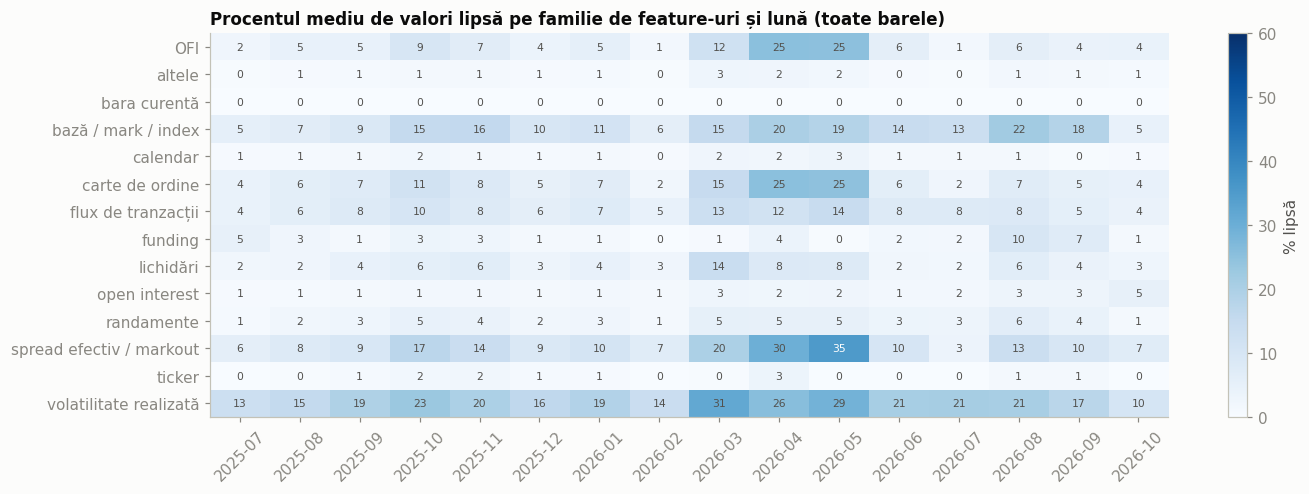

In [3]:
QM = QSTAT.assign(nf=QSTAT["null"] / QSTAT["n"]).pivot(index="col", columns="month", values="nf")
order = [c for c in bs["columns"] if c in QM.index]
QM = QM.loc[order]
G = QSTAT.groupby("col").agg(n=("n", "sum"), null=("null", "sum"), inf=("inf", "sum"), min_std=("std", "min")).loc[order]
G["lipsă %"] = 100 * G["null"] / G["n"]; G["luna cea mai proastă %"] = 100 * QM.max(1); G["luna"] = QM.idxmax(1)
print(f"{len(G)} coloane numerice. Valori infinite: {int(G['inf'].sum())}. Coloane constante în cel puțin o lună: {int((G['min_std'] == 0).sum())} "
      f"({', '.join(G.index[G['min_std'] == 0][:8])}, ...).")
print(f"Coloane cu > 50% lipsă pe tot setul: {int((G['lipsă %'] > 50).sum())}; > 10%: {int((G['lipsă %'] > 10).sum())}; ≤ 1%: {int((G['lipsă %'] <= 1).sum())}.")
display(G.sort_values("lipsă %", ascending=False).head(25)[["lipsă %", "luna cea mai proastă %", "luna"]].round(1))

def family(c):
    for pat, name in [(r"^bar_", "bara curentă"), (r"^(ret_trade|path_eff)", "randamente"), (r"^(rv_|bv_|jump_|max_abs)", "volatilitate realizată"),
                      (r"_(5s|30s|2m)(_|$)", None), (r"^(liq_|time_since)", "lichidări"), (r"^(oi_|turnover)", "open interest"), (r"^(funding|settle)", "funding"),
                      (r"^(mark|index|basis|ret_index|ret_mark|ret_trade_minus|tw_basis|std_basis)", "bază / mark / index"), (r"^ticker_", "ticker"),
                      (r"^(hour|day_of|is_weekend|notional_15m_vs)", "calendar"), (r"^(ofi|mlofi)", "OFI"), (r"^(eff_spread|markout)", "spread efectiv / markout")]:
        if name and re.search(pat, c):
            return name
    if re.search(r"(bid|ask|qi_|spread|depth|cost_|conc_|gap_|pressure|book|cert)", c):
        return "carte de ordine"
    if re.search(r"^(tw_state|trade_count|volume_|notional|trade_rate|tfi|count_imb|mean_trade|size_conc|large_trade|signed_large|vwap|range_log|close_loc|drawdown|rebound|trade_size|sign_acf|run_|burst|activity)", c):
        return "flux de tranzacții"
    return "altele"
FAM = pd.Series({c: family(c) for c in QM.index})
fam_month = QM.groupby(FAM).mean()
fig, ax = plt.subplots(figsize=(13, 4.6))
im = ax.imshow(100 * fam_month.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=60)
ax.set_yticks(range(len(fam_month)), fam_month.index); ax.set_xticks(range(fam_month.shape[1]), fam_month.columns, rotation=45)
ax.grid(False); ax.set_title("Procentul mediu de valori lipsă pe familie de feature-uri și lună (toate barele)")
for i in range(fam_month.shape[0]):
    for j in range(fam_month.shape[1]):
        v = 100 * fam_month.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 35 else INK2)
fig.colorbar(im, ax=ax, label="% lipsă"); fig.tight_layout(); plt.show()

## 1. Verificarea datasetului

Fiecare lună e citită integral. Verific invarianții barei: timp monoton, `bar_id` unic, `eval_time ≤ decision_time`, L ≤ O, C ≤ H, VWAP în [L, H], |tfi_ratio| ≤ 1, identitatea tfi_ratio = tfi/V, spread ≥ 0, |qi_1| ≤ 1 și randamentul egal cu log(C/C₋₁). Apoi măsor, pentru fiecare dintre cele 666 de coloane, valorile lipsă, cele infinite și coloanele constante, lună cu lună.B

In [4]:
BASE_COLS = ["decision_time_ns", "t_start_ns", "complete", "feed_complete", "book_state", "bar_close", "bar_high", "bar_low", "bar_return_log",
             "ret_trade_15m", "last_trade_age_ms", "bar_duration_s"]
B = pd.concat([pq.read_table(f, columns=BASE_COLS).to_pandas() for f in FILES], ignore_index=True)
B = B.sort_values("decision_time_ns", kind="mergesort").reset_index(drop=True)
B.index = pd.DatetimeIndex(pd.to_datetime(B["decision_time_ns"], utc=True), name="t")
tns = B["decision_time_ns"].to_numpy()
cl, hi, lo = B["bar_close"].to_numpy(), B["bar_high"].to_numpy(), B["bar_low"].to_numpy()
ok_bar = (B["complete"].to_numpy() == 1) & (B["feed_complete"].to_numpy() == 1)

# Leakage screen on all bars: no feature should "predict" the NEXT bar's return strongly (a feature built with future data would).
def leak_screen():
    rng = np.random.default_rng(SEED)
    out = {}
    nxt = np.r_[B["bar_return_log"].to_numpy()[1:], np.nan]
    prv = B["bar_return_log"].to_numpy()
    pos_by_month, start = [], 0
    for f in FILES:
        n = pq.ParquetFile(f).metadata.num_rows
        pos_by_month.append((f, start, n)); start += n
    pick = np.sort(rng.choice(len(B), 200_000, replace=False))
    parts = []
    for f, s0, n in pos_by_month:
        sel = pick[(pick >= s0) & (pick < s0 + n)] - s0
        t = pq.read_table(f).to_pandas()
        assert np.array_equal(t["decision_time_ns"].to_numpy(), tns[s0:s0 + n]), "ordinea fișierelor diferă de ordinea temporală"
        parts.append(t.iloc[sel].select_dtypes(include=[np.number]))
    S = pd.concat(parts, ignore_index=True)
    y_next, y_prev = nxt[pick], prv[pick]
    for c in S.columns:
        x = S[c].to_numpy(float); m = np.isfinite(x) & np.isfinite(y_next) & np.isfinite(y_prev)
        if m.sum() < 1000 or np.nanstd(x[m]) == 0:
            continue
        out[c] = (spearmanr(x[m], y_next[m])[0], spearmanr(x[m], y_prev[m])[0], m.sum())
    return pd.DataFrame(out, index=["IC cu randamentul barei următoare", "IC cu randamentul barei curente", "n"]).T
LEAK = cached("leak", leak_screen)
LEAK["|IC următor|"] = LEAK.iloc[:, 0].abs()
print("Cele mai mari corelații (Spearman) cu randamentul barei URMĂTOARE, pe 200.000 de bare aleatoare:")
display(LEAK.sort_values("|IC următor|", ascending=False).head(12).round(4))
print(f"Feature-uri cu |IC următor| > 0.05: {int((LEAK['|IC următor|'] > 0.05).sum())} din {len(LEAK)}; > 0.2: {int((LEAK['|IC următor|'] > 0.2).sum())}.")

# Where does this next-bar "predictability" come from? Volume bars close on a volume threshold, often in the middle of one aggressive order.
def sweep_check():
    cols = ["decision_time_ns", "t_open_recv_ns", "m_open_ms", "m_close_ms", "bar_close", "run_sign", "tfi_ratio_5s", "close_location_5s", "qi_1"]
    S = pd.concat([pq.read_table(f, columns=cols).to_pandas() for f in FILES], ignore_index=True)
    same_ms = S["m_open_ms"].to_numpy()[1:] == S["m_close_ms"].to_numpy()[:-1]
    gap_us = (S["t_open_recv_ns"].to_numpy()[1:] - S["decision_time_ns"].to_numpy()[:-1]) / 1e3
    tn, c = S["decision_time_ns"].to_numpy(), S["bar_close"].to_numpy()
    rows = []
    for lat in (0.0, 0.1, 1.0, 5.0):
        j = np.minimum(np.searchsorted(tn, tn + int(lat * 1e9) + (1 if lat == 0 else 0), side="left"), len(tn) - 2)
        jump, after = np.log(c[j] / c), np.log(c[j + 1] / c[j])
        for f_ in ("run_sign", "tfi_ratio_5s", "close_location_5s", "qi_1"):
            x = S[f_].to_numpy(float); m = np.isfinite(x) & np.isfinite(jump) & np.isfinite(after)
            sub = np.flatnonzero(m)[::7]
            rows.append({"latență (s)": lat, "feature": f_, "IC cu saltul semnal → intrare": spearmanr(x[sub], jump[sub])[0],
                         "IC cu bara de după intrare": spearmanr(x[sub], after[sub])[0]})
    return same_ms.mean(), np.percentile(gap_us, [25, 50, 75, 90]), pd.DataFrame(rows)
SAME_MS, GAP_Q, SWEEP = cached("sweep", sweep_check)
print(f"{100 * SAME_MS:.1f}% din bare se închid în aceeași milisecundă de piață în care începe bara următoare; distanța de recepție până la tranzacția următoare: "
      f"percentilele 25/50/75/90 = {GAP_Q[0]:.0f} / {GAP_Q[1]:.0f} / {GAP_Q[2]:.0f} / {GAP_Q[3]:.0f} µs.")
display(SWEEP.pivot(index="feature", columns="latență (s)", values=["IC cu saltul semnal → intrare", "IC cu bara de după intrare"]).round(3))

Cele mai mari corelații (Spearman) cu randamentul barei URMĂTOARE, pe 200.000 de bare aleatoare:


,IC cu randamentul barei următoare,IC cu randamentul barei curente,n,|IC următor|
run_sign,0.1849,0.2268,199282.0,0.1849
close_location_5s,0.1455,0.4693,198900.0,0.1455
tfi_ratio_5s,0.1426,0.4185,199053.0,0.1426
signed_large_flow_5s_usdt,0.1144,0.3674,199053.0,0.1144
pressure_net_5bps_5s,0.1143,0.4020,188733.0,0.1143
tfi_5s_usdt,0.1133,0.4037,199053.0,0.1133
tfi_5s_btc,0.1126,0.4054,199053.0,0.1126
tfi_over_tw_depth1_5s,0.1111,0.4150,189232.0,0.1111
count_imbalance_5s,0.1104,0.5100,199053.0,0.1104
qi_1,0.0978,0.2016,190833.0,0.0978


Feature-uri cu |IC următor| > 0.05: 77 din 650; > 0.2: 0.
75.1% din bare se închid în aceeași milisecundă de piață în care începe bara următoare; distanța de recepție până la tranzacția următoare: percentilele 25/50/75/90 = 6 / 12 / 229 / 40689 µs.


IC cu saltul semnal → intrare                      IC cu bara de după intrare                     
latență (s)                                 0.0    0.1    1.0    5.0                        0.0    0.1    1.0    5.0
feature                                                                                                             
close_location_5s                         0.144  0.142  0.133  0.116                      0.021  0.013  0.010  0.005
qi_1                                      0.096  0.092  0.089  0.081                      0.001  0.002  0.002 -0.001
run_sign                                  0.184  0.181  0.170  0.149                      0.021  0.012  0.012  0.007
tfi_ratio_5s                              0.142  0.139  0.129  0.110                      0.024  0.015  0.013  0.008

**Barele de volum se închid în mijlocul unui sweep.** 75% din bare se termină în aceeași milisecundă de piață în care începe bara următoare. Tranzacția următoare sosește în mediană la 12 µs după cea care închide bara. Un singur ordin agresiv este deci tăiat în două bare. De aceea `run_sign`, `tfi_ratio_5s`, `close_location_5s` și `qi_1` au IC 0,10–0,18 cu bara următoare. Tabelul arată însă că acest IC se află **în saltul dintre semnal și intrare**. După o latență de 0,1–1 s, IC cu bara de după intrare scade la ~0,01.

Efectul este real, dar nu poate fi tranzacționat. Dacă intrarea s-ar face chiar la prețul de închidere al barei-semnal, etichetele ar conține acest câștig imposibil. **De aceea intrarea are loc la închiderea primei bare aflate la ≥ 1 s după semnal.**

## 2. Filtrul CUSUM și strategia primară

**Filtrul CUSUM** este cel simetric (AFML 2.5.2.1), aplicat pe randamentele logaritmice ale barelor și resetat la goluri de date. Pragul este adaptiv: h = 0,5·σ₆₀, unde σ₆₀ este abaterea standard a randamentului pe 60 min, estimată pe ultimele 24 h strict înainte de bară. Strategia primară tranzacționează **doar** la evenimentele CUSUM. Folosește **momentum**: long dacă a declanșat S⁺, short dacă a declanșat S⁻.

**Triple barrier.** Barierele orizontale sunt la ±h în jurul prețului de intrare (aceeași scară ca filtrul). Bariera verticală este la 60 min după semnal. O bară care atinge stop-ul iese la cel mai prost preț al barei. O bară care atinge ambele bariere contează ca stop.

**Meta-label:** y = 1 dacă tranzacția primarei are randament brut pozitiv. Ponderea fiecărui eveniment este unicitatea medie a etichetei (AFML cap. 4).

In [5]:
r15 = B["ret_trade_15m"].where(B["last_trade_age_ms"] <= 10_000)
SIG60 = (2 * np.sqrt((r15 ** 2).rolling("24h", closed="left", min_periods=500).mean())).to_numpy()   # sigma of a 60-min return, trailing 24 h

@njit
def cusum_filter(r, h):
    # Symmetric CUSUM (Lopez de Prado, AFML 2.5.2.1) on bar log returns; resets on data gaps.
    n = r.size; sp = 0.0; sn = 0.0
    side = np.zeros(n, np.int8); excess = np.full(n, np.nan)
    for i in range(n):
        if not (np.isfinite(r[i]) and np.isfinite(h[i])):
            sp = 0.0; sn = 0.0; continue
        sp = max(0.0, sp + r[i]); sn = min(0.0, sn + r[i])
        if sp >= h[i]:
            side[i] = 1; excess[i] = sp / h[i] - 1; sp = 0.0; sn = 0.0
        elif sn <= -h[i]:
            side[i] = -1; excess[i] = -sn / h[i] - 1; sp = 0.0; sn = 0.0
    return side, excess

r_bar = np.where(ok_bar, B["bar_return_log"].to_numpy(), np.nan)
H_CUSUM = CUSUM_K * SIG60
CS_SIDE, CS_EXCESS = cusum_filter(r_bar, H_CUSUM)
K0 = np.flatnonzero((CS_SIDE != 0) & (tns >= START.value) & (tns < DATA_END.value - (HORIZON_MIN + 10) * 60 * 10**9))
KE = np.minimum(np.searchsorted(tns, tns[K0] + int(LATENCY_S * 1e9), side="left"), len(tns) - 1)      # entry bar
EV = pd.DataFrame({"k": K0, "ke": KE, "t0": B.index[K0], "t0_ns": tns[K0], "side": CS_SIDE[K0].astype(int), "h": H_CUSUM[K0], "excess": CS_EXCESS[K0],
                   "p_signal": cl[K0], "p0": cl[KE], "entry_delay_s": (tns[KE] - tns[K0]) / 1e9})
EV["w"] = BARRIER_K * EV["h"]
inc = incident_rows(B["t_start_ns"].to_numpy()[K0] - 15 * 60 * 10**9, tns[K0] + HORIZON_MIN * 60 * 10**9, man["quality_incidents"])
EV["eligible"] = np.isin(B["book_state"].to_numpy()[K0], [0, 9]) & ok_bar[K0] & ok_bar[KE] & (EV["entry_delay_s"] <= 600).to_numpy() & ~inc     # 10 min: data-validity guard only (a tighter limit would select on the future bar's duration)
EV["slip_bps"] = 1e4 * EV["side"] * np.log(EV["p0"] / EV["p_signal"])        # move between the signal and the entry, in the trade's direction
ndays = (DATA_END - START).days
gap = np.diff(EV["t0_ns"]) / 6e10
print(f"{len(EV):,} evenimente CUSUM ({len(EV) / ndays:.1f} pe zi), long {np.mean(EV['side'] > 0):.1%}. Pragul h: mediana {1e4 * np.nanmedian(EV['h']):.1f} bps "
      f"(percentile 10/90: {1e4 * EV['h'].quantile(.1):.1f} / {1e4 * EV['h'].quantile(.9):.1f}). Distanța între evenimente: mediana {np.median(gap):.1f} min, "
      f"percentila 10 {np.percentile(gap, 10):.1f} min. Eligibile la intrare: {EV['eligible'].mean():.1%}.")

27,936 evenimente CUSUM (58.6 pe zi), long 49.7%. Pragul h: mediana 29.3 bps (percentile 10/90: 15.0 / 52.6). Distanța între evenimente: mediana 13.3 min, percentila 10 2.2 min. Eligibile la intrare: 96.1%.


In [6]:
@njit
def resolve(k0, side, w, t_end, tns, hi, lo, cl, ok):    # k0 = entry bars
    # reason: 0 valid, 1 incomplete bar (trade-feed gap) inside the window, 2 no bar within 10 minutes of the vertical barrier.
    # A bar that touches the stop exits at the bar's worst price; a bar touching both barriers counts as a stop (conservative).
    n = k0.size
    lab = np.zeros(n, np.int8); exitp = np.full(n, np.nan); exit_t = np.zeros(n, np.int64); reason = np.zeros(n, np.int8)
    for i in range(n):
        k = k0[i]; P0 = cl[k]; up = P0 * np.exp(w[i]); dn = P0 * np.exp(-w[i])
        j = k + 1; lastj = -1; done = False
        while j < tns.size and tns[j] <= t_end[i]:
            if not ok[j]:
                reason[i] = 1; break
            hu = hi[j] >= up; hd = lo[j] <= dn
            if hu or hd:
                if side[i] > 0:
                    if hd:
                        lab[i] = -1; exitp[i] = lo[j]
                    else:
                        lab[i] = 1; exitp[i] = up
                else:
                    if hu:
                        lab[i] = -1; exitp[i] = hi[j]
                    else:
                        lab[i] = 1; exitp[i] = dn
                exit_t[i] = tns[j]; done = True; break
            lastj = j; j += 1
        if reason[i] == 0 and not done:
            if lastj < 0 or t_end[i] - tns[lastj] > 600 * 10**9:
                reason[i] = 2
            else:
                exitp[i] = cl[lastj]; exit_t[i] = tns[lastj]
    return lab, exitp, exit_t, reason

t_end = tns[K0] + HORIZON_MIN * 60 * 10**9
lab, exitp, exit_t, reason = resolve(KE, EV["side"].to_numpy(), EV["w"].to_numpy(), t_end, tns, hi, lo, cl, ok_bar)
EV["barrier"], EV["exit_p"], EV["t1_ns"], EV["reason"] = lab, exitp, exit_t, reason
EV["gross"] = EV["side"] * (EV["exit_p"] / EV["p0"] - 1)
EV["y"] = (EV["gross"] > 0).astype(int)                 # meta-label: the primary's trade made money before costs
EV["hold_min"] = (EV["t1_ns"] - EV["t0_ns"]) / 6e10
EV["use"] = EV["eligible"] & (EV["reason"] == 0) & np.isfinite(EV["h"])
rng = np.random.default_rng(1)
for i in rng.choice(np.flatnonzero(EV["use"]), 300, replace=False):     # independent check of the first barrier touch with pandas
    k = KE[i]; seg = B.iloc[k + 1:].loc[lambda d: d["decision_time_ns"] <= t_end[i]]
    up, dn = EV.at[i, "p0"] * np.exp(EV.at[i, "w"]), EV.at[i, "p0"] * np.exp(-EV.at[i, "w"])
    tch = np.flatnonzero((seg["bar_high"] >= up) | (seg["bar_low"] <= dn))
    assert (EV.at[i, "barrier"] != 0) == (tch.size > 0)
    if tch.size:
        assert seg["decision_time_ns"].iloc[tch[0]] == EV.at[i, "t1_ns"]
print("Verificarea independentă a primei atingeri de barieră pe 300 de evenimente: OK.")
print(f"Utilizabile: {EV['use'].sum():,} din {len(EV):,}. Excluse: {int((~EV['eligible']).sum())} neeligibile la intrare (book invalid, bară incompletă, incident), "
      f"{int((EV['eligible'] & (EV['reason'] == 1)).sum())} cu gol în fluxul de tranzacții în fereastra etichetei, {int((EV['eligible'] & (EV['reason'] == 2)).sum())} fără bară la bariera verticală.")
U = EV[EV["use"]]
print(f"Rezultatul barierelor: TP {np.mean(U['barrier'] == 1):.1%}, SL {np.mean(U['barrier'] == -1):.1%}, verticală {np.mean(U['barrier'] == 0):.1%}. "
      f"Durata medie {U['hold_min'].mean():.1f} min (mediana {U['hold_min'].median():.1f}). Meta-label y=1: {U['y'].mean():.1%}.")

Verificarea independentă a primei atingeri de barieră pe 300 de evenimente: OK.
Utilizabile: 25,362 din 27,936. Excluse: 1089 neeligibile la intrare (book invalid, bară incompletă, incident), 1484 cu gol în fluxul de tranzacții în fereastra etichetei, 1 fără bară la bariera verticală.
Rezultatul barierelor: TP 39.8%, SL 39.9%, verticală 20.3%. Durata medie 26.8 min (mediana 20.2). Meta-label y=1: 49.0%.


Latența de intrare: întârzierea până la bara de intrare: mediana 9.7 s, percentila 90 58 s, > 10 min (exclus): 0; mișcarea de preț între semnal și intrare, în direcția tranzacției: medie +0.11 bps (o primară momentum plătește acest salt, una de reversie îl câștigă).
Unicitatea medie a etichetelor: 0.723 (1 = fără suprapunere). Concurență maximă: 12 etichete simultane.
Strategia primară (momentum pe direcția evenimentului CUSUM), câte o tranzacție pe eveniment, fără selecție:


tranzacții  rata de câștig  medie (bps)  t-stat  |brut| mediu (bps)
toate                             cost 0 bps      25362.0           0.490       -1.066  -5.183              28.056
                                  cost 4 bps      25362.0           0.468       -5.066 -24.627              28.056
                                  cost 10 bps     25362.0           0.427      -11.066 -53.792              28.056
descoperire (iul 2025 – feb 2026) cost 0 bps      13275.0           0.488       -1.160  -3.901              29.118
                                  cost 4 bps      13275.0           0.467       -5.160 -17.353              29.118
                                  cost 10 bps     13275.0           0.430      -11.160 -37.530              29.118
validare (mar – oct 2026)         cost 0 bps      12087.0           0.492       -0.963  -3.413              26.890
                                  cost 4 bps      12087.0           0.469       -4.963 -17.584              26.890
                                  cost 10 bps     12087.0           0.423      -10.963 -38.840              26.890
doar long                         cost 0 bps      12605.0           0.492       -0.914  -3.155              27.724
                                  cost 4 bps      12605.0           0.467       -4.914 -16.955              27.724
                                  cost 10 bps     12605.0           0.425      -10.914 -37.655              27.724
doar short                        cost 0 bps      12757.0           0.488       -1.216  -4.166              28.385
                                  cost 4 bps      12757.0           0.469       -5.216 -17.866              28.385
                                  cost 10 bps     12757.0           0.429      -11.216 -38.416              28.385

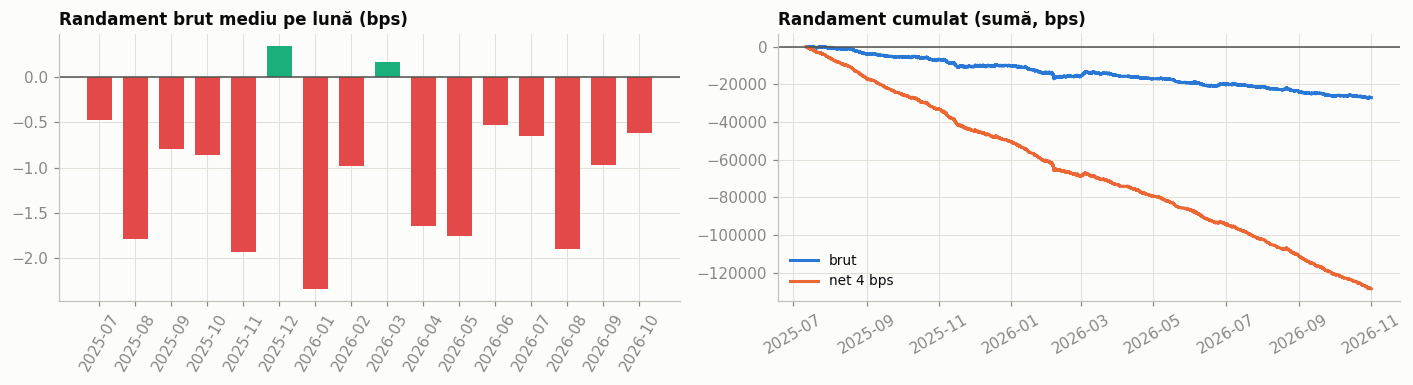

In [7]:
print(f"Latența de intrare: întârzierea până la bara de intrare: mediana {EV['entry_delay_s'].median():.1f} s, percentila 90 {EV['entry_delay_s'].quantile(.9):.0f} s, "
      f"> 10 min (exclus): {int((EV['entry_delay_s'] > 600).sum())}; mișcarea de preț între semnal și intrare, "
      f"în direcția tranzacției: medie {EV.loc[EV['use'], 'slip_bps'].mean():+.2f} bps (o primară momentum plătește acest salt, una de reversie îl câștigă).")
EV = EV[EV["use"]].reset_index(drop=True)
K0 = EV["k"].to_numpy()
def avg_uniqueness(t0, t1):
    # Exact average uniqueness (AFML ch. 4): mean over each label's life of 1 / number of concurrent labels.
    t1 = np.maximum(t1, t0 + 1)
    pts = np.unique(np.r_[t0, t1])
    conc = np.zeros(pts.size - 1)
    a, b = np.searchsorted(pts, t0), np.searchsorted(pts, t1)
    d = np.zeros(pts.size); np.add.at(d, a, 1); np.add.at(d, b, -1)
    conc = np.cumsum(d)[:-1]
    seg = np.diff(pts) * np.where(conc > 0, 1.0 / np.maximum(conc, 1), 0.0)
    cum = np.r_[0.0, np.cumsum(seg)]
    return (cum[b] - cum[a]) / (t1 - t0), conc
EV["u"], _conc = avg_uniqueness(EV["t0_ns"].to_numpy(), EV["t1_ns"].to_numpy())
AVG_U = EV["u"].mean()
print(f"Unicitatea medie a etichetelor: {AVG_U:.3f} (1 = fără suprapunere). Concurență maximă: {int(_conc.max())} etichete simultane.")

def perf(g, cost):
    r = g - cost / 1e4
    return {"tranzacții": len(r), "rata de câștig": (r > 0).mean(), "medie (bps)": 1e4 * r.mean(), "t-stat": r.mean() / r.std() * np.sqrt(len(r)),
            "|brut| mediu (bps)": 1e4 * np.abs(g).mean()}
rows = {}
for nm, msk in [("toate", np.ones(len(EV), bool)), ("descoperire (iul 2025 – feb 2026)", EV["t0"] < DISC_END), ("validare (mar – oct 2026)", EV["t0"] >= DISC_END),
                ("doar long", EV["side"] > 0), ("doar short", EV["side"] < 0)]:
    for c in COSTS:
        rows[(nm, f"cost {c} bps")] = perf(EV.loc[msk, "gross"].to_numpy(), c)
PRIM = pd.DataFrame(rows).T
print("Strategia primară (momentum pe direcția evenimentului CUSUM), câte o tranzacție pe eveniment, fără selecție:")
display(PRIM.round(3))
mon = EV.groupby(EV["t0"].dt.strftime("%Y-%m")).agg(evenimente=("gross", "size"), castig=("y", "mean"), brut_bps=("gross", lambda x: 1e4 * x.mean()), h_bps=("h", lambda x: 1e4 * x.median()))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].bar(mon.index, mon["brut_bps"], color=[C["aqua"] if v > 0 else C["red"] for v in mon["brut_bps"]], width=.7)
axes[0].axhline(0, color=INK2, lw=1); axes[0].set_title("Randament brut mediu pe lună (bps)"); axes[0].tick_params(axis="x", rotation=60)
gc = np.cumsum(EV["gross"].to_numpy())
axes[1].plot(EV["t0"], 1e4 * gc, color=C["blue"], label="brut"); axes[1].plot(EV["t0"], 1e4 * (gc - np.arange(1, len(EV) + 1) * 4e-4), color=C["orange"], label="net 4 bps")
axes[1].axhline(0, color=INK2, lw=1); axes[1].set_title("Randament cumulat (sumă, bps)"); axes[1].legend(); axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout(); plt.show()

**Strategia primară.** Câștigă 49,0% din tranzacții și pierde **−1,07 bps brut** (t = −5,2). Rezultatul e la fel în ambele perioade, pentru long și pentru short. TP și SL sunt atinse în proporții egale (39,8% și 39,9%). Pierderea brută vine în mare parte din regula conservatoare de ieșire: stop-ul iese la cel mai prost preț al barei, take-profit-ul exact la barieră.

O primară de reversie ar avea meta-label-ul aproape complementar. Cu bariere simetrice, problema de meta-labeling este deci, în esență, **direcția mișcării de după un eveniment CUSUM**. Un filtru ar fi util doar dacă feature-urile ar prezice această direcție.

## 3. Matricea de feature-uri

**Excluse:** identitatea barei, metadatele de calitate (exclus implicit și de `chdds`), codurile de stare, vârsta datelor, contoarele și acoperirea, cadența feed-ului de carte (măsoară feed-ul, nu activitatea), nivelurile de preț și de open interest (nestaționare).

**Orientarea după direcția tranzacției.** Un meta-model trebuie să judece feature-urile relativ la direcția tranzacției. Un RF cu `max_features=1` învață greu interacțiunea cu `side`, așa că orientarea se face explicit:

* `o_` = feature semnat, înmulțit cu direcția (pozitiv = în favoarea tranzacției);
* `own_` / `opp_` = membrul unei perechi bid/ask, buy/sell, pos/neg sau lichidări short/long care susține, respectiv se opune tranzacției;
* `ev_` = feature calculat din seria de bare (σ, randamente și volatilitate pe 1h/4h/24h fără ferestre stricte, timpul de la evenimentul anterior, numărul de evenimente din ultimele 4h).

**Curățare.**

* eliminate feature-urile cu > 10% lipsă la evenimente;
* transformare log sau asinh pentru cozi grele, winsorizare la 0,5/99,5%, standardizare, imputare cu mediana (≤ 10% pe coloană);
* eliminată câte o copie din fiecare grup de aproape-duplicate (|ρ Spearman| ≥ 0,95).

**Placebo: 40 de feature-uri** adăugate în fiecare test, ca referință. 38 sunt feature-uri reale decalate circular cu 25–75% din eșantion: au aceeași distribuție și aceeași autocorelație, dar nicio legătură cu etichetele. Două sunt zgomot gaussian. Un feature real e „peste placebo” doar dacă îl depășește pe cel mai bun dintre ele.

In [8]:
META = META_COLS; QUALITY = QUALITY_COLS
DROP_RULES = [
    ("cod de stare / calitate", r"^(tw_state_|mark_state$|oi_state$|liq_state_|ticker_state$|liq_inferred_zero_)|_censored$"),
    ("vârsta datelor (calitatea feed-ului)", r"(_age_ms|_age_s)$|^oi_reference_ts_ns$"),
    ("acoperire / număr de observații", r"^(book_coverage_|basis_coverage_|basis_mark_index_coverage_|rv_n_returns_|eff_spread_n_|oi_points_received_|oi_ref_dtau_known_)|^markout_\d+s_n_|^oi_reference_dtau_s$|^ticker_window_s$|^funding_interval_s_observed$"),
    ("cadența feed-ului de book (nu activitate)", r"^(book_msg_count_|book_level_changes_)"),
    ("nivel de preț (nestaționar)", r"^(bar_open|bar_high|bar_low|bar_close|bar_vwap|last_trade_price|mark_price|index_price|best_bid|best_ask|mid|oi_value_price_implied)$|^vwap_(5s|30s|2m|15m|1h)$"),
    ("nivel de open interest (nestaționar)", r"^(oi_btc_asof|oi_usdt_asof|oi_btc_known_delayed)$|^tw_oi_known_"),
    ("pragul adaptiv al barei / redundant", r"^(bar_threshold_btc|time_to_funding_s)$"),
]
LONG_TOK = {"bid": "ask", "buy": "sell", "pos": "neg", "short": "long"}
SWAP = {**LONG_TOK, **{v: k for k, v in LONG_TOK.items()}}
SIGNED = re.compile(r"^(ret_|bar_return_log$|bar_oc_log$|bar_tfi_|tfi_\d|tfi_ratio_(5s|30s|2m|15m|1h)$|count_imbalance_|bar_count_imbalance$|signed_large_flow_|"
                    r"vwap_distance_|ticker_vwap_distance|ticker_return$|path_efficiency_|rv_asym_|run_sign$|qi_|tw_qi_|weighted_mid_offset|ofi_|mlofi_|pressure_net_|"
                    r"liq_signed_|liq_imbalance_|basis_|tw_basis_|funding_rate_asof$|funding_change_|funding_rz_7d$|settle_est_index|funding_x_oi_|tfi_over_tw_depth1_)")
UNIT = re.compile(r"^(close_location_|bar_close_location$|ticker_range_position_trade$)")
UNSIGNED_EXC = re.compile(r"^(tfi_ratio_x_|std_basis_)")

def drop_reason(c):
    if c in META:
        return "identitate / timp al barei"
    if c in QUALITY:
        return "metadate de calitate (excluse de chdds)"
    for why, pat in DROP_RULES:
        if re.search(pat, c):
            return why
    return None

def classify(cols):
    out, cs = {}, set(cols)
    for c in cols:
        r = drop_reason(c)
        if r:
            out[c] = ("exclus", r); continue
        if c.startswith(("drawdown_from_high_", "rebound_from_low_")):
            out[c] = ("sus/jos", None); continue
        if UNSIGNED_EXC.search(c):
            out[c] = ("nesemnat", None); continue
        toks = c.split("_")
        p = "_".join(SWAP.get(t, t) for t in toks) if any(t in SWAP for t in toks) else None
        if p is not None and p in cs:
            out[c] = ("pereche", (p, any(t in LONG_TOK for t in toks))); continue
        if UNIT.search(c):
            out[c] = ("semnat [0,1]", None); continue
        out[c] = ("semnat", None) if SIGNED.search(c) else ("nesemnat", None)
    return out

COLS = bs["columns"]
CLS = classify(COLS)
cls_tab = pd.Series({c: (k if k != "exclus" else f"exclus: {e}") for c, (k, e) in CLS.items()}).value_counts()
print("Clasificarea celor", len(COLS), "coloane:"); display(cls_tab.to_frame("coloane"))

def load_event_rows():
    need = [c for c in COLS if CLS[c][0] != "exclus"]
    parts, start = [], 0
    for f in FILES:
        n = pq.ParquetFile(f).metadata.num_rows
        sel = K0[(K0 >= start) & (K0 < start + n)] - start
        t = pq.read_table(f, columns=["decision_time_ns"] + need).to_pandas()
        assert np.array_equal(t["decision_time_ns"].to_numpy(), tns[start:start + n])
        parts.append(t.iloc[sel]); start += n
    R = pd.concat(parts, ignore_index=True)
    assert np.array_equal(R["decision_time_ns"].to_numpy(), EV["t0_ns"].to_numpy())
    return R.drop(columns="decision_time_ns")
RAW = cached("event_rows", load_event_rows)
print(f"Matricea brută la evenimente: {RAW.shape[0]:,} evenimente × {RAW.shape[1]} coloane.")

Clasificarea celor 666 coloane:


,coloane
nesemnat,233
semnat,161
pereche,130
exclus: acoperire / număr de observații,41
exclus: identitate / timp al barei,18
exclus: nivel de preț (nestaționar),17
exclus: cod de stare / calitate,17
exclus: vârsta datelor (calitatea feed-ului),12
sus/jos,10
exclus: cadența feed-ului de book (nu activitate),10


Matricea brută la evenimente: 25,362 evenimente × 541 coloane.


In [9]:
side = EV["side"].to_numpy().astype(float)
F = {}
done = set()
for c in RAW.columns:
    kind, extra = CLS[c]
    x = RAW[c].to_numpy(float)
    if kind == "nesemnat":
        F[c] = x
    elif kind == "semnat":
        F["o_" + c] = side * x
    elif kind == "semnat [0,1]":
        F["o_" + c] = side * (x - 0.5)
    elif kind == "sus/jos" and c.startswith("rebound_from_low_"):
        w_ = c[len("rebound_from_low_"):]
        up, dn = x, -RAW["drawdown_from_high_" + w_].to_numpy(float)       # distance above the window low / below the window high (both >= 0)
        F["own_move_from_extreme_" + w_] = np.where(side > 0, up, dn)       # move already made in the trade's direction
        F["opp_move_from_extreme_" + w_] = np.where(side > 0, dn, up)
    elif kind == "pereche" and c not in done:
        p, own_long = extra
        a, b_ = (x, RAW[p].to_numpy(float)) if own_long else (RAW[p].to_numpy(float), x)
        base = c if own_long else p
        F["own_" + base] = np.where(side > 0, a, b_)
        F["opp_" + base] = np.where(side > 0, b_, a)
        done |= {c, p}
F["o_run_length_signed"] = side * RAW["run_sign"].to_numpy(float) * RAW["run_length_trades"].to_numpy(float)

# Event-level features computed from the bar series (gap tolerant, unlike the strict 1h/4h/24h windows of the dataset).
hE = EV["h"].to_numpy(); tE = EV["t0_ns"].to_numpy()
def asof_ret(lag_min):
    j = np.searchsorted(tns, tE - lag_min * 60 * 10**9, side="right") - 1
    okj = (j >= 0) & (tE - lag_min * 60 * 10**9 - tns[np.maximum(j, 0)] <= 5 * 60 * 10**9)
    return np.where(okj, np.log(cl[K0] / cl[np.maximum(j, 0)]), np.nan)
r2c = np.r_[0.0, np.cumsum(np.nan_to_num(r_bar) ** 2)]
def rv_bars(lag_min):
    j = np.searchsorted(tns, tE - lag_min * 60 * 10**9, side="right")
    return r2c[K0 + 1] - r2c[j]
F["ev_log_h"] = np.log(hE)
F["ev_cusum_excess"] = EV["excess"].to_numpy()
for L in (60, 240, 1440):
    F[f"ev_o_ret_{L}m_over_h"] = side * asof_ret(L) / hE
for L in (60, 240):
    F[f"ev_rv_{L}m_over_h2"] = rv_bars(L) / hE ** 2
allk = np.flatnonzero(CS_SIDE != 0); alls = CS_SIDE[allk]
pos_in_all = np.searchsorted(allk, K0)
prev_t = np.where(pos_in_all > 0, tns[allk[np.maximum(pos_in_all - 1, 0)]], np.nan)
F["ev_min_since_prev_event"] = np.clip((tE - prev_t) / 6e10, 0, 24 * 60)
F["ev_prev_event_same_side"] = np.where(pos_in_all > 0, (alls[np.maximum(pos_in_all - 1, 0)] == EV["side"].to_numpy()).astype(float), np.nan)
F["ev_events_last_4h"] = pos_in_all - np.searchsorted(tns[allk], tE - 4 * 3600 * 10**9)
F["ev_o_side_balance_last_4h"] = side * np.array([alls[a:b].sum() / max(b - a, 1) for a, b in zip(np.searchsorted(tns[allk], tE - 4 * 3600 * 10**9), pos_in_all)])
F["side"] = side
X_ALL = pd.DataFrame(F)
print(f"După orientare: {X_ALL.shape[1]} feature-uri (o_ = semnat și înmulțit cu direcția; own_/opp_ = partea care susține / se opune tranzacției; ev_ = calculate din seria de bare).")

După orientare: 554 feature-uri (o_ = semnat și înmulțit cu direcția; own_/opp_ = partea care susține / se opune tranzacției; ev_ = calculate din seria de bare).


In [10]:
miss = X_ALL.isna().mean()
nunq = X_ALL.nunique()
DROP_MISS = miss[miss > 0.10].index.tolist()
DROP_CONST = nunq[nunq <= 1].index.tolist()
keep = [c for c in X_ALL.columns if c not in DROP_MISS and c not in DROP_CONST]
print(f"Eliminate: {len(DROP_MISS)} cu > 10% lipsă la evenimente (ferestre stricte de 1h/4h/24h, bandă de 50 bps, ferestre de 15m din carte), {len(DROP_CONST)} constante.")
print("   exemple:", ", ".join(miss[DROP_MISS].sort_values(ascending=False).index[:12]))

def transform(col):
    x = col.to_numpy(float)
    f = x[np.isfinite(x)]
    if f.size == 0:
        return x
    if f.min() >= 0 and pd.Series(f).skew() > 2:
        med = np.median(f[f > 0]) if (f > 0).any() else 1.0
        x = np.log1p(x / med)
    elif pd.Series(f).kurt() > 10:
        s = np.median(np.abs(f - np.median(f))) or np.std(f) or 1.0
        x = np.arcsinh(x / s)
    lo_, hi_ = np.nanpercentile(x, [0.5, 99.5])
    return np.clip(x, lo_, hi_)
XT = pd.DataFrame({c: transform(X_ALL[c]) for c in keep})
XT = XT.fillna(XT.median())          # at most 10% per column; the median is taken over the whole sample (explanatory study, not a trading backtest)
XT = XT.loc[:, XT.std() > 0]          # clipping can make a very sparse column constant (for example liq_any_30s)
XT = (XT - XT.mean()) / XT.std()

# Near-duplicates: keep the first (registry order) of any group with |Spearman| >= 0.95.
RHO = XT.rank().corr().to_numpy()
cols_ = list(XT.columns); kept, dup_of = [], {}
for i, c in enumerate(cols_):
    j = next((cols_.index(k) for k in kept if abs(RHO[i, cols_.index(k)]) >= 0.95), None)
    if j is None:
        kept.append(c)
    else:
        dup_of[c] = cols_[j]
if "side" not in kept:
    kept.append("side")
XR = XT[kept].copy()
print(f"Duplicate aproape perfecte eliminate (|ρ| ≥ 0,95 cu un feature păstrat): {len(dup_of)}. Rămân {XR.shape[1]} feature-uri reale.")
DUP = pd.Series(dup_of, name="reprezentat de")
display(DUP.groupby(DUP).apply(lambda s: ", ".join(s.index[:6]) + (" ..." if len(s) > 6 else "")).to_frame("duplicate eliminate").head(20))

# Placebo features: circular shifts of real features (same distribution and autocorrelation, no alignment with the labels) plus Gaussian noise.
rng = np.random.default_rng(SEED)
N_PLAC = 10 if QUICK else 38
src = rng.choice([c for c in kept if c != "side"], N_PLAC, replace=False)
n_ev = len(XR)
for i, c in enumerate(src):
    XR[f"PLACEBO_{i:02d}_{c}"] = np.roll(XR[c].to_numpy(), int(rng.integers(int(0.25 * n_ev), int(0.75 * n_ev))))
for i in range(2):
    XR[f"PLACEBO_gauss_{i}"] = rng.standard_normal(n_ev)
PLAC = [c for c in XR.columns if c.startswith("PLACEBO_")]
REAL = [c for c in XR.columns if c not in PLAC]
y = EV["y"].to_numpy(); wgt = EV["u"].to_numpy() / EV["u"].mean()
t0n, t1n = EV["t0_ns"].to_numpy(), EV["t1_ns"].to_numpy()
print(f"Matricea finală: {n_ev:,} evenimente × {len(REAL)} feature-uri reale + {len(PLAC)} placebo.")

Eliminate: 94 cu > 10% lipsă la evenimente (ferestre stricte de 1h/4h/24h, bandă de 50 bps, ferestre de 15m din carte), 0 constante.
   exemple: max_abs_ret_trade_24h_grid1m, jump_trade_24h_grid1m, rv_trade_24h_grid1m, own_rv_pos_trade_24h_grid1m, opp_rv_pos_trade_24h_grid1m, o_rv_asym_trade_24h_grid1m, bv_trade_24h_grid1m, notional_rate_ratio_5s_vs_24h, notional_rate_ratio_2m_vs_24h, notional_rate_ratio_30s_vs_24h, notional_rate_ratio_1h_vs_24h, notional_rate_ratio_15m_vs_24h


Duplicate aproape perfecte eliminate (|ρ| ≥ 0,95 cu un feature păstrat): 118. Rămân 342 feature-uri reale.


,duplicate eliminate
reprezentat de,
bar_duration_s,"bar_volume_rate_btc_s, bar_notional_rate_usdt_s"
eff_spread_qw_bps_2m,eff_spread_dw_bps_2m
eff_spread_qw_bps_30s,eff_spread_dw_bps_30s
liq_count_15m,liq_rate_15m_per_s
liq_count_1h,liq_rate_1h_per_s
liq_count_2m,liq_rate_2m_per_s
liq_count_30s,liq_rate_30s_per_s
log1p_liq_notional_15m,"liq_notional_rate_15m_usdt_s, liq_peak_1s_15m_..."
log1p_liq_notional_1h,"liq_notional_rate_1h_usdt_s, liq_to_oi_1h"


Matricea finală: 25,362 evenimente × 342 feature-uri reale + 40 placebo.


## 4. Validare încrucișată și configurarea modelului

* **Purged K-Fold cu embargo** (5 fold-uri contigue în timp). Din antrenare se scot evenimentele a căror etichetă [t₀, t₁] se suprapune cu perioada de test (purge), plus cele care încep în ziua de după test (embargo de 1 zi, cât fereastra cea mai lungă a feature-urilor folosite).
* **Random Forest cu `max_features=1`.** Fiecare nod alege un singur feature la întâmplare, așa că feature-urile dominante nu le pot masca pe celelalte (AFML 8.3.1). Restul configurației:
  * entropie, 500 de arbori;
  * `max_samples` = unicitatea medie a etichetelor (0,72);
  * clase echilibrate, ponderi de unicitate;
  * frunze cu ≥ 0,2% din greutate (~50 de evenimente), ca probabilitățile să fie utilizabile în log loss.
* **Metrica:** câștigul de log loss ponderat față de prognoza constantă 0,5, în milinați (mnats). Plus AUC.

Modelul cu toate cele 342 de feature-uri reale obține AUC 0,506 și −0,2 mnats. Modelul doar cu placebo obține AUC 0,497. Diferența dintre ele e de ordinul a ce variază de la un fold la altul.

In [11]:
def purged_kfold(t0, t1, n_splits=N_SPLITS, embargo=EMBARGO, idx=None):
    """Contiguous folds in time; drop training events whose label span overlaps the test span (purge) or that start within `embargo` after it."""
    idx = np.arange(len(t0)) if idx is None else np.asarray(idx)
    out = []
    for te in np.array_split(idx, n_splits):
        a, b = t0[te[0]], t1[te].max()
        tr = idx[~(((t1[idx] >= a) & (t0[idx] <= b)) | ((t0[idx] > b) & (t0[idx] <= b + embargo.value)))]
        out.append((tr, te))
    return out
FOLDS = purged_kfold(t0n, t1n)
for i, (tr, te) in enumerate(FOLDS):
    print(f"fold {i}: test {EV['t0'].iloc[te[0]]:%Y-%m-%d} – {EV['t0'].iloc[te[-1]]:%Y-%m-%d} ({len(te):,}), train {len(tr):,} "
          f"(eliminate prin purge + embargo: {n_ev - len(te) - len(tr)})")

from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp
def pmap(fn, items, workers=WORKERS):
    """Fork-based process pool: workers inherit the data (no pickling of matrices); results come back in order."""
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("fork")) as ex:
        return list(ex.map(fn, items))

def make_rf(n_trees=N_TREES, seed=SEED, max_samples=None, n_jobs=None, min_leaf=None):
    # max_features=1: every split looks at a single random feature, so dominant features cannot mask the others (AFML 8.3.1).
    return RandomForestClassifier(n_estimators=n_trees, criterion="entropy", max_features=1, max_samples=max_samples or AVG_U, bootstrap=True,
                                  min_weight_fraction_leaf=min_leaf or MIN_LEAF, class_weight="balanced_subsample", n_jobs=n_jobs or WORKERS, random_state=seed)

def wll(y_, p, w_):
    return log_loss(y_, np.clip(p, 1e-6, 1 - 1e-6), sample_weight=w_, labels=[0, 1])

def prior_ll(y_, w_):
    # log loss of a constant 0.5 forecast, the reference for a model trained with balanced classes
    return wll(y_, np.full(len(y_), 0.5), w_)

def cv_scores(X, cols, folds, n_trees=N_TREES, seed=SEED, n_jobs=None, min_leaf=None):
    ll, auc, oof = [], [], np.full(len(X), np.nan)
    A = X[cols].to_numpy(np.float32)
    for i, (tr, te) in enumerate(folds):
        rf = make_rf(n_trees, seed + i, n_jobs=n_jobs, min_leaf=min_leaf).fit(A[tr], y[tr], sample_weight=wgt[tr])
        p = rf.predict_proba(A[te])[:, 1]; oof[te] = p
        ll.append(prior_ll(y[te], wgt[te]) - wll(y[te], p, wgt[te])); auc.append(roc_auc_score(y[te], p, sample_weight=wgt[te]))
    return np.array(ll), np.array(auc), oof

def mdi(X, cols, n_trees=N_TREES, seed=SEED, idx=None, yy=None, n_jobs=None):
    idx = np.arange(len(X)) if idx is None else idx
    yy = y if yy is None else yy
    rf = make_rf(n_trees, seed, n_jobs=n_jobs).fit(X[cols].to_numpy(np.float32)[idx], yy[idx], sample_weight=wgt[idx])
    imp = np.array([t.feature_importances_ for t in rf.estimators_])
    imp[imp == 0] = np.nan            # 0 = the feature was never drawn in that tree (max_features=1), not "useless"
    m = np.nanmean(imp, 0); s = np.nanstd(imp, 0) / np.sqrt(np.sum(np.isfinite(imp), 0))
    m, s = np.nan_to_num(m), np.nan_to_num(s)          # never split on in any tree (e.g. a nearly constant binary column): importance 0
    return pd.DataFrame({"mean": m / np.nansum(m), "se": s / np.nansum(m)}, index=cols)

def _mda_fold(args):
    A, cols, tr, te, yy, n_trees, seed, n_rep, n_jobs = args
    rf = make_rf(n_trees, seed, n_jobs=n_jobs).fit(A[tr], yy[tr], sample_weight=wgt[tr])
    Xt = A[te]; nt = len(te); rng_ = np.random.default_rng(seed)
    s0 = wll(yy[te], rf.predict_proba(Xt)[:, 1], wgt[te])
    out = np.zeros(len(cols)); step = max(1, 48 // n_rep)
    for j0 in range(0, len(cols), step):              # several permuted copies in one predict call (much faster than one call per column)
        js = list(range(j0, min(len(cols), j0 + step)))
        big = np.tile(Xt, (len(js) * n_rep, 1))
        for q, j in enumerate(js):
            for r in range(n_rep):
                b0 = (q * n_rep + r) * nt
                big[b0:b0 + nt, j] = rng_.permutation(Xt[:, j])
        P = rf.predict_proba(big)[:, 1]
        for q, j in enumerate(js):
            out[j] = np.mean([wll(yy[te], P[(q * n_rep + r) * nt:(q * n_rep + r + 1) * nt], wgt[te]) for r in range(n_rep)]) - s0
    return 1e3 * out, prior_ll(yy[te], wgt[te]) - s0

def mda(X, cols, folds, n_trees=N_TREES, seed=SEED, n_rep=2, yy=None, parallel_folds=True, n_jobs=None):
    """Permutation importance, out of sample, on purged folds. Importance = rise in weighted log loss (millinats) when the column is shuffled."""
    yy = y if yy is None else yy
    A = X[cols].to_numpy(np.float32)
    nj = max(1, WORKERS // len(folds)) if parallel_folds else (n_jobs or WORKERS)
    args = [(A, cols, tr, te, yy, n_trees, seed + i, n_rep, nj) for i, (tr, te) in enumerate(folds)]
    res = pmap(_mda_fold, args, workers=len(folds)) if parallel_folds else [_mda_fold(a) for a in args]
    D = np.array([r[0] for r in res])
    out = pd.DataFrame({"mean": D.mean(0), "se": D.std(0, ddof=1) / np.sqrt(len(folds))}, index=cols)
    out.attrs["base_gain_mnats"] = 1e3 * np.mean([r[1] for r in res]); out.attrs["per_fold"] = pd.DataFrame(D, columns=cols)
    return out

def sfi(X, cols, folds, n_trees=N_TREES_SFI, seed=SEED):
    """Single feature importance: each feature alone, out of sample. Gain over the 0.5 forecast in weighted log loss (millinats) and AUC."""
    def one(c):
        ll, auc, _ = cv_scores(X, [c], folds, n_trees, seed, n_jobs=1, min_leaf=MIN_LEAF_SFI)
        return {"mean": 1e3 * ll.mean(), "se": 1e3 * ll.std(ddof=1) / np.sqrt(len(ll)), "auc": auc.mean(), "auc_se": auc.std(ddof=1) / np.sqrt(len(auc))}
    global _SFI_ONE
    _SFI_ONE = one
    return pd.DataFrame(pmap(_sfi_call, cols), index=cols)
def _sfi_call(c):
    return _SFI_ONE(c)

t = time.time()
LL_ALL, AUC_ALL, OOF_ALL = cached("cv_all", lambda: cv_scores(XR, REAL, FOLDS))
LL_PL, AUC_PL, _ = cached("cv_plac", lambda: cv_scores(XR, PLAC, FOLDS))
print(f"Model cu toate {len(REAL)} feature-urile reale, purged {N_SPLITS}-fold: câștig de log loss față de prognoza 0,5 = {1e3 * LL_ALL.mean():+.2f} mnats "
      f"(pe fold-uri: {', '.join(f'{1e3 * v:+.1f}' for v in LL_ALL)}); AUC {AUC_ALL.mean():.3f} ± {AUC_ALL.std(ddof=1) / np.sqrt(N_SPLITS):.3f}.")
print(f"Model doar cu cele {len(PLAC)} feature-uri placebo: câștig {1e3 * LL_PL.mean():+.2f} mnats; AUC {AUC_PL.mean():.3f}. ({time.time() - t:.0f} s)")

fold 0: test 2025-07-12 – 2025-10-02 (5,073), train 20,227 (eliminate prin purge + embargo: 62)
fold 1: test 2025-10-02 – 2026-01-01 (5,073), train 20,178 (eliminate prin purge + embargo: 111)
fold 2: test 2026-01-01 – 2026-04-21 (5,072), train 20,242 (eliminate prin purge + embargo: 48)
fold 3: test 2026-04-21 – 2026-08-01 (5,072), train 20,252 (eliminate prin purge + embargo: 38)
fold 4: test 2026-08-01 – 2026-10-31 (5,072), train 20,289 (eliminate prin purge + embargo: 1)
Model cu toate 342 feature-urile reale, purged 5-fold: câștig de log loss față de prognoza 0,5 = -0.23 mnats (pe fold-uri: +0.0, +0.1, -1.2, +0.1, -0.1); AUC 0.506 ± 0.003.
Model doar cu cele 40 feature-uri placebo: câștig -0.58 mnats; AUC 0.497. (0 s)


## 5. MDI, MDA și SFI pe feature-urile originale

* **MDI** (in-sample): media reducerii impurității pe arbori. **Valorile de 0 devin NaN înainte de mediere**, fiindcă 0 înseamnă doar că feature-ul nu a fost extras în acel arbore. Rezultatul e normalizat la sumă 1.
* **MDA** (out-of-sample, purged CV): creșterea log loss-ului pe fold-ul de test când coloana e permutată (2 permutări pe fold). Criteriul: mai mare decât maximul placebo **și** medie − 2·SE > 0.
* **SFI** (out-of-sample, purged CV): fiecare feature singur, într-un RF de 100 de arbori cu frunze ≥ 1%. Este singura metodă imună la substituție. Un singur feature dă oricum un model care supra-învață puțin, așa că toate valorile de log loss sunt negative. Criteriul este deci relativ: feature-ul trebuie să depășească toate placebo-urile atât la log loss, cât și la AUC.

**Referința de șansă.** Dacă niciun feature nu are semnal, fiecare are probabilitatea 1/41 să depășească maximul a 40 de placebo, adică ~8 din 342 pe fiecare metodă. Placebo-urile evaluate leave-one-out dau rata empirică.

In [12]:
FEATS = REAL + PLAC
t = time.time()
MDI = cached("mdi_full", lambda: mdi(XR, FEATS))
MDA = cached("mda_full", lambda: mda(XR, FEATS, FOLDS))
print(f"MDI + MDA: {time.time() - t:.0f} s"); t = time.time()
SFI = cached("sfi_full", lambda: sfi(XR, FEATS, FOLDS))
print(f"SFI: {time.time() - t:.0f} s")

def summarize(MDI, MDA, SFI, real, plac):
    """Pass = above the maximum of the placebo features (for a placebo row: the maximum of the OTHER placebos, which estimates the chance pass rate)."""
    T = pd.DataFrame({"MDI": MDI["mean"].fillna(0), "MDA (mnats)": MDA["mean"], "MDA se": MDA["se"], "SFI (mnats)": SFI["mean"], "SFI se": SFI["se"], "SFI AUC": SFI["auc"]})
    thr = {}
    def loo_max(k):
        pv = T.loc[plac, k]; out = pd.Series(pv.max(), index=T.index)
        for p_ in plac:
            out[p_] = pv.drop(p_).max()
        return out
    for k in ("MDI", "MDA (mnats)", "SFI (mnats)", "SFI AUC"):
        thr[k] = T.loc[plac, k].max()
    T["MDI > placebo"] = T["MDI"] > loo_max("MDI")
    T["MDA > placebo"] = (T["MDA (mnats)"] > loo_max("MDA (mnats)")) & (T["MDA (mnats)"] - 2 * T["MDA se"] > 0)
    # Single-feature forests pay an over-fitting penalty in log loss (every SFI value is below zero), so SFI is judged against the placebos on both scales.
    T["SFI > placebo"] = (T["SFI (mnats)"] > loo_max("SFI (mnats)")) & (T["SFI AUC"] > loo_max("SFI AUC"))
    T["metode trecute"] = T[["MDI > placebo", "MDA > placebo", "SFI > placebo"]].sum(1)
    for k in ("MDI", "MDA (mnats)", "SFI (mnats)"):
        T[f"rang {k.split()[0]}"] = T[k].rank(ascending=False).astype(int)
    return T, thr

def chance_table(T, real, plac):
    rows = {}
    for k in ("MDI > placebo", "MDA > placebo", "SFI > placebo"):
        rows[k.split()[0]] = {"feature-uri reale care trec": int(T.loc[real, k].sum()), "rata de trecere a placebo (leave-one-out)": T.loc[plac, k].mean(),
                              "așteptat din întâmplare": len(real) / (len(plac) + 1)}
    rows["≥ 2 metode"] = {"feature-uri reale care trec": int((T.loc[real, "metode trecute"] >= 2).sum()), "rata de trecere a placebo (leave-one-out)": (T.loc[plac, "metode trecute"] >= 2).mean(),
                          "așteptat din întâmplare": np.nan}
    return pd.DataFrame(rows).T

TAB, THR = summarize(MDI, MDA, SFI, REAL, PLAC)
print(f"Praguri placebo (maximul peste cele {len(PLAC)} placebo): MDI {THR['MDI']:.4f}, MDA {THR['MDA (mnats)']:.3f} mnats, SFI {THR['SFI (mnats)']:.3f} mnats și AUC {THR['SFI AUC']:.4f}. "
      f"Cel mai bun SFI real: {TAB.loc[REAL, 'SFI (mnats)'].max():.3f} mnats; cel mai bun AUC SFI real: {TAB.loc[REAL, 'SFI AUC'].max():.4f}.")
print(f"Feature-uri reale peste placebo — MDI: {int(TAB.loc[REAL, 'MDI > placebo'].sum())}, MDA: {int(TAB.loc[REAL, 'MDA > placebo'].sum())}, "
      f"SFI: {int(TAB.loc[REAL, 'SFI > placebo'].sum())}; în toate trei: {int((TAB.loc[REAL, 'metode trecute'] == 3).sum())}; în cel puțin două: {int((TAB.loc[REAL, 'metode trecute'] >= 2).sum())}.")
print(f"Referința de șansă: dacă niciun feature nu ar avea semnal, fiecare ar avea probabilitatea 1/{len(PLAC) + 1} să depășească maximul a {len(PLAC)} placebo, "
      f"adică ~{len(REAL) / (len(PLAC) + 1):.0f} din {len(REAL)} feature-uri reale pe fiecare metodă.")
display(chance_table(TAB, REAL, PLAC).round(3))
display(TAB.loc[REAL].sort_values(["metode trecute", "MDA (mnats)"], ascending=False).head(30).round(4))

MDI + MDA: 0 s
SFI: 0 s
Praguri placebo (maximul peste cele 40 placebo): MDI 0.0030, MDA 0.023 mnats, SFI -0.117 mnats și AUC 0.5136. Cel mai bun SFI real: 0.037 mnats; cel mai bun AUC SFI real: 0.5174.
Feature-uri reale peste placebo — MDI: 5, MDA: 7, SFI: 0; în toate trei: 0; în cel puțin două: 0.
Referința de șansă: dacă niciun feature nu ar avea semnal, fiecare ar avea probabilitatea 1/41 să depășească maximul a 40 placebo, adică ~8 din 342 feature-uri reale pe fiecare metodă.


,feature-uri reale care trec,rata de trecere a placebo (leave-one-out),așteptat din întâmplare
MDI,5.0,0.025,8.341
MDA,7.0,0.000,8.341
SFI,0.0,0.000,8.341
≥ 2 metode,0.0,0.000,NaN


,MDI,MDA (mnats),MDA se,SFI (mnats),SFI se,SFI AUC,MDI > placebo,MDA > placebo,SFI > placebo,metode trecute,rang MDI,rang MDA,rang SFI
markout_1s_qw_bps_2m,0.0028,0.0384,0.0142,-3.4560,0.7338,0.5030,False,True,False,1,145,1,98
o_liq_imbalance_30s,0.0009,0.0346,0.0084,-0.2463,0.1158,0.5029,False,True,False,1,371,2,14
mean_trade_size_5s_btc,0.0027,0.0302,0.0095,-3.9826,0.5472,0.5017,False,True,False,1,164,4,194
o_funding_x_oi_level_rz,0.0027,0.0291,0.0124,-4.1177,0.5330,0.5007,False,True,False,1,168,5,224
trade_size_p90_2m_usdt,0.0028,0.0269,0.0108,-2.6334,0.6924,0.5174,False,True,False,1,95,6,39
own_cost_buy_0p1btc_bps,0.0028,0.0262,0.0096,-3.3685,1.2525,0.5079,False,True,False,1,135,7,88
o_mlofi_norm_l5_30s,0.0026,0.0260,0.0097,-3.9528,0.4637,0.5031,False,True,False,1,286,8,185
o_qi_25bps,0.0031,0.0222,0.0247,-3.5807,0.6793,0.5032,True,False,False,1,3,17,115
day_of_week_sin,0.0032,0.0186,0.0175,-4.4933,0.5586,0.5048,True,False,False,1,1,26,301
ev_o_ret_60m_over_h,0.0031,0.0021,0.0113,-5.0460,0.3153,0.4986,True,False,False,1,2,148,361


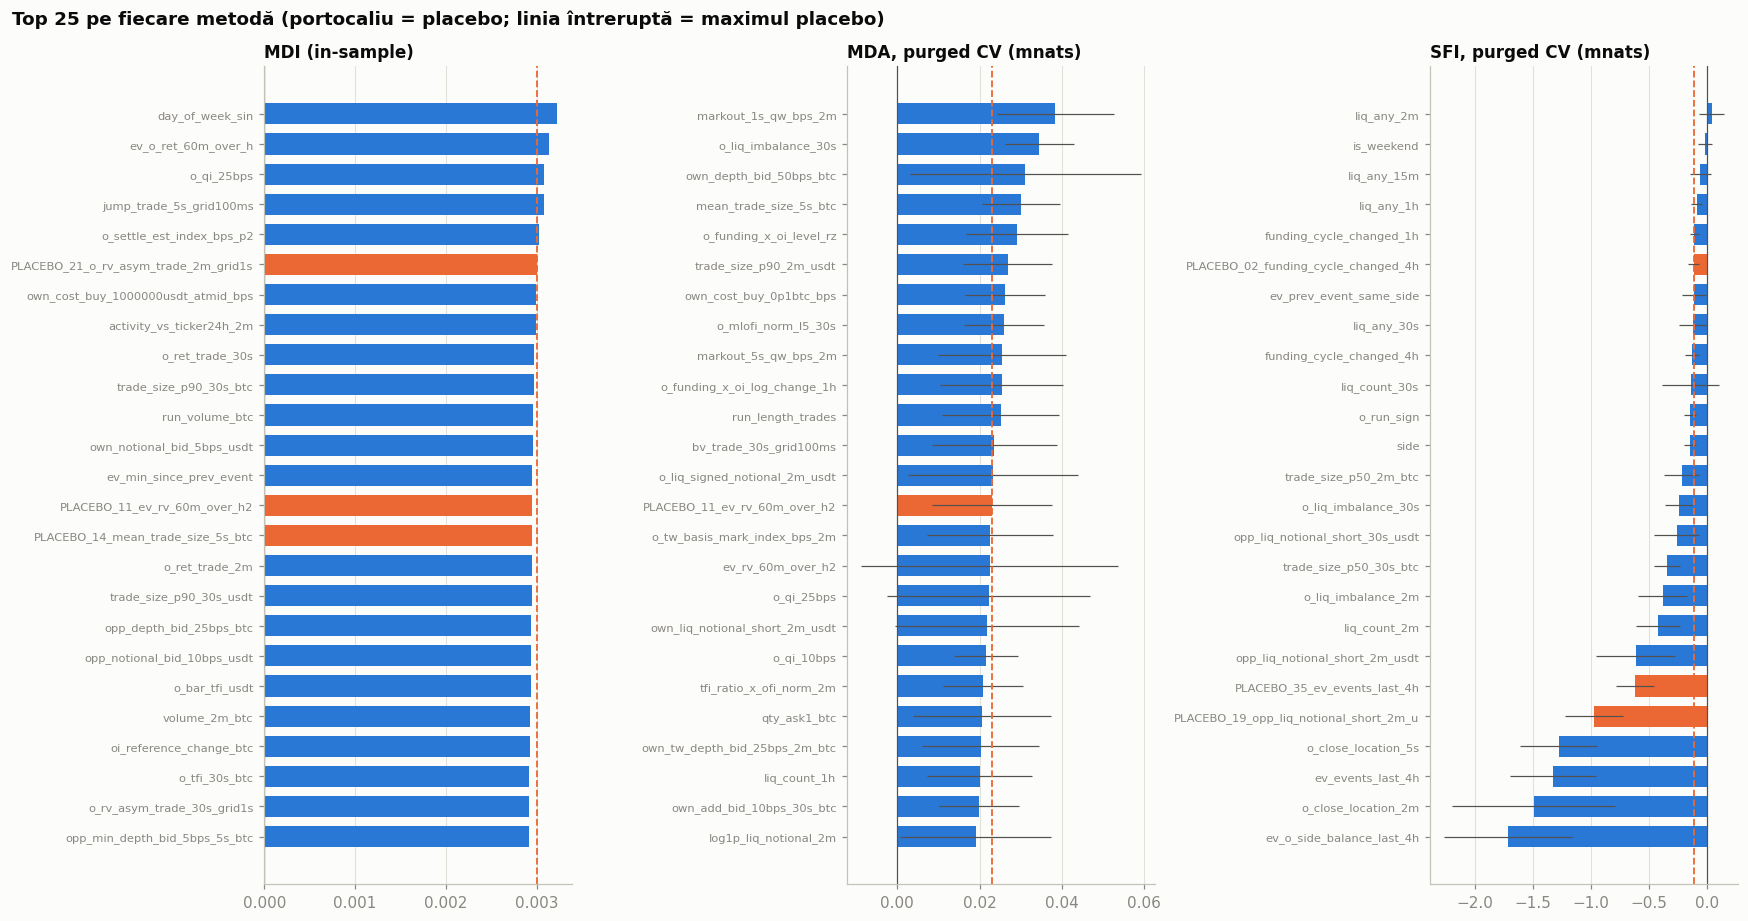

In [13]:
def imp_plot(ax, df, col, se, title, top=25, thr=None):
    d = df.sort_values(col, ascending=False).head(top)[::-1]
    colors = [C["orange"] if i.startswith("PLACEBO") else C["blue"] for i in d.index]
    ax.barh(range(len(d)), d[col], xerr=None if se is None else d[se], color=colors, height=.7, error_kw=dict(ecolor=INK2, lw=.8))
    ax.set_yticks(range(len(d)), [i[:38] for i in d.index], fontsize=7.5)
    if thr is not None:
        ax.axvline(thr, color=C["orange"], lw=1.2, ls="--")
    ax.axvline(0, color=INK2, lw=.8); ax.set_title(title); ax.grid(axis="y", visible=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 8.5))
imp_plot(axes[0], TAB, "MDI", None, "MDI (in-sample)", thr=THR["MDI"])
imp_plot(axes[1], TAB, "MDA (mnats)", "MDA se", "MDA, purged CV (mnats)", thr=THR["MDA (mnats)"])
imp_plot(axes[2], TAB, "SFI (mnats)", "SFI se", "SFI, purged CV (mnats)", thr=THR["SFI (mnats)"])
fig.suptitle("Top 25 pe fiecare metodă (portocaliu = placebo; linia întreruptă = maximul placebo)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); plt.show()

**Interpretare.** Câte feature-uri trec pe fiecare metodă e **sub nivelul de șansă**: MDI 5, MDA 7, SFI 0, față de ~8 așteptate. Niciun feature nu trece două metode. Valorile MDA sunt de câteva sutimi de milinat; un model cu un câștig total de ~0 nu are ce împărți între feature-uri. Cel mai bun AUC SFI real (0,517) e de ordinul celui mai bun placebo (0,514).

În topurile individuale apar familii plauzibile: imbalanța cărții orientată (`o_qi_*`), markout-ul, mărimea tranzacțiilor, funding × OI. Ordinea lor nu se distinge însă de cea a unor feature-uri decalate în timp.

## 6. Ortogonalizare PCA și testul Kendall τ ponderat

MDI și MDA suferă de substituție: două feature-uri corelate își împart importanța. Remediul cerut este PCA pe matricea standardizată (fără `side`), urmat de MDI/MDA pe componentele ortogonale. Păstrez componentele care explică 95% din varianță.

**Confirmarea ex-ante.** τ ponderat (`scipy.stats.weightedtau`) între importanța componentelor și inversul rangului PCA. Dacă importanța supravegheată ar urma ordinea nesupravegheată a varianței, τ ar fi mare. Pentru calibrare am calculat distribuția lui τ cu etichetele amestecate aleator: 30 de permutări pentru MDI, 10 pentru MDA.

In [14]:
Zr = XR[REAL].drop(columns="side").to_numpy()
evals, evecs = np.linalg.eigh(np.cov(Zr, rowvar=False))
o = np.argsort(evals)[::-1]; evals, evecs = evals[o], evecs[:, o]
cumv = np.cumsum(evals) / evals.sum()
N_PC = int(np.searchsorted(cumv, 0.95) + 1)
PCS = [f"PC{i + 1}" for i in range(N_PC)]
XP = pd.DataFrame(Zr @ evecs[:, :N_PC], columns=PCS)
XP["side"] = XR["side"].to_numpy()
PC_RANK = np.arange(1, N_PC + 1)
LOAD = pd.DataFrame(evecs[:, :N_PC], index=[c for c in REAL if c != "side"], columns=PCS)
print(f"PCA pe {Zr.shape[1]} feature-uri standardizate: {N_PC} componente explică 95% din varianță (PC1 {100 * evals[0] / evals.sum():.1f}%, "
      f"primele 10: {100 * cumv[9]:.1f}%). Direcția tranzacției (side) rămâne separată, nu intră în PCA.")
t = time.time()
MDI_PC = cached("mdi_pc", lambda: mdi(XP, PCS + ["side"]))
MDA_PC = cached("mda_pc", lambda: mda(XP, PCS + ["side"], FOLDS))
LL_PC, AUC_PC, _ = cached("cv_pc", lambda: cv_scores(XP, PCS + ["side"], FOLDS))
print(f"({time.time() - t:.0f} s) Model pe componente: câștig {1e3 * LL_PC.mean():+.2f} mnats, AUC {AUC_PC.mean():.3f} (pe fold-uri: {', '.join(f'{v:.3f}' for v in AUC_PC)}); "
      f"modelul pe feature-urile originale: AUC pe fold-uri {', '.join(f'{v:.3f}' for v in AUC_ALL)}. Rotația PCA folosește tot eșantionul (fără etichete); testul curat este walk-forward-ul din secțiunea 9.")

def wtau(imp):
    return weightedtau(imp.loc[PCS].to_numpy(), 1.0 / PC_RANK)[0]
TAU = {"MDI": wtau(MDI_PC["mean"]), "MDA": wtau(MDA_PC["mean"])}
# Null distribution of tau: the same procedure with the labels shuffled (the link between X and y is destroyed, everything else kept).
N_PERM_MDI = 6 if QUICK else 30
N_PERM_MDA = 3 if QUICK else 10
def _tau_perm(r_):
    yp = np.random.default_rng(SEED + 100 + r_).permutation(y)
    a = wtau(mdi(XP, PCS + ["side"], N_TREES_SMALL, SEED + r_, yy=yp, n_jobs=1)["mean"])
    b = wtau(mda(XP, PCS + ["side"], FOLDS, N_TREES_SMALL, SEED + r_, n_rep=1, yy=yp, parallel_folds=False, n_jobs=1)["mean"]) if r_ < N_PERM_MDA else np.nan
    return a, b
def tau_null():
    res = pmap(_tau_perm, range(N_PERM_MDI))
    return {"MDI": [a for a, _ in res], "MDA": [b for _, b in res if np.isfinite(b)]}
t = time.time()
TAU_NULL = cached("tau_null", tau_null)
print(f"({time.time() - t:.0f} s)")
TAUT = pd.DataFrame({"tau ponderat (etichete reale)": TAU, "medie sub etichete amestecate": {k: np.mean(v) for k, v in TAU_NULL.items()},
                     "maxim sub etichete amestecate": {k: np.max(v) for k, v in TAU_NULL.items()},
                     "percentila reală în distribuția nulă": {k: 100 * np.mean(np.array(v) < TAU[k]) for k, v in TAU_NULL.items()},
                     "permutări": {k: len(v) for k, v in TAU_NULL.items()}})
display(TAUT.round(3))

PCA pe 341 feature-uri standardizate: 141 componente explică 95% din varianță (PC1 21.7%, primele 10: 54.4%). Direcția tranzacției (side) rămâne separată, nu intră în PCA.
(0 s) Model pe componente: câștig +0.42 mnats, AUC 0.518 (pe fold-uri: 0.512, 0.517, 0.529, 0.520, 0.510); modelul pe feature-urile originale: AUC pe fold-uri 0.507, 0.510, 0.493, 0.513, 0.507. Rotația PCA folosește tot eșantionul (fără etichete); testul curat este walk-forward-ul din secțiunea 9.
(0 s)


,tau ponderat (etichete reale),medie sub etichete amestecate,maxim sub etichete amestecate,percentila reală în distribuția nulă,permutări
MDI,0.038,-0.032,0.219,76.667,30
MDA,-0.087,0.006,0.112,10.000,10


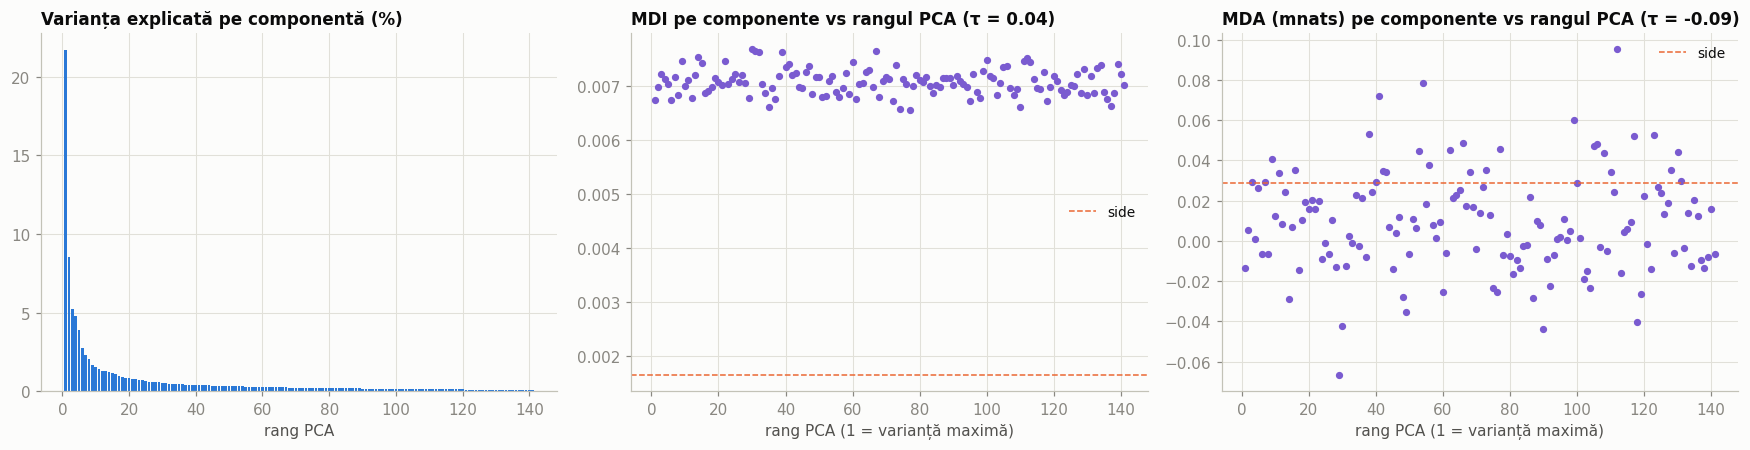

Componentele cu cel mai mare MDA și ce conțin:


,MDA (mnats),MDA se,varianță %,feature-uri dominante (încărcare)
componentă,,,,
PC112,0.095,0.026,0.120,"oi_level_rz_7d (+0.23), oi_log_change_known_24..."
PC54,0.078,0.022,0.300,"day_of_week_sin (+0.29), o_mlofi_norm_l2_30s (..."
PC41,0.072,0.015,0.396,"liq_any_15m (-0.29), log1p_liq_notional_15m (-..."
PC99,0.060,0.031,0.143,"own_depth_bid_50bps_btc (+0.24), ev_cusum_exce..."
PC38,0.053,0.047,0.416,"oi_level_rz_7d (+0.28), oi_log_change_known_24..."
PC123,0.053,0.013,0.103,"opp_liq_notional_short_30s_usdt (+0.22), size_..."


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].bar(PC_RANK, 100 * evals[:N_PC] / evals.sum(), color=C["blue"], width=.8); axes[0].set_title("Varianța explicată pe componentă (%)"); axes[0].set_xlabel("rang PCA")
for ax, (nm, d) in zip(axes[1:], [("MDI", MDI_PC), ("MDA (mnats)", MDA_PC)]):
    v = d.loc[PCS, "mean"].to_numpy()
    ax.scatter(PC_RANK, v, s=14, color=C["purple"]); ax.axhline(d.loc["side", "mean"], color=C["orange"], lw=1, ls="--", label="side")
    ax.set_title(f"{nm} pe componente vs rangul PCA (τ = {TAU[nm.split()[0]]:.2f})"); ax.set_xlabel("rang PCA (1 = varianță maximă)"); ax.legend()
fig.tight_layout(); plt.show()
top_pc = MDA_PC.loc[PCS].sort_values("mean", ascending=False).head(6)
rows = []
for pc, r_ in top_pc.iterrows():
    l = LOAD[pc]; tops = l.abs().sort_values(ascending=False).head(6).index
    rows.append({"componentă": pc, "MDA (mnats)": r_["mean"], "MDA se": r_["se"], "varianță %": 100 * evals[int(pc[2:]) - 1] / evals.sum(),
                 "feature-uri dominante (încărcare)": ", ".join(f"{c} ({l[c]:+.2f})" for c in tops)})
print("Componentele cu cel mai mare MDA și ce conțin:")
display(pd.DataFrame(rows).set_index("componentă").round(3))

**Interpretare.**

* **τ ponderat nu confirmă nimic.** Pentru MDI este 0,04 (percentila 77 a distribuției cu etichete amestecate, al cărei maxim este 0,22). Pentru MDA este −0,09 (percentila 10). Ambele sunt departe de pragul de 0,8.
* **Componentele cu cel mai mare MDA explică foarte puțină varianță** (PC112: 0,12%, PC54: 0,3%). Ele amestecă zile ale săptămânii, OI, lichidări și adâncime: un tipar de supra-învățare, nu un factor de piață.
* **Modelul pe componente** are un AUC ceva mai mare (0,518, peste modelul pe feature-uri originale în fiecare fold). Rotația PCA a folosit însă tot eșantionul. Secțiunea 9 o refac lunar, doar pe trecut.

## 7. Stivuire (features stacking) vs evaluare paralelă

Metoda cerută stivuiește activele standardizate ale unui univers într-o singură matrice. Datasetul conține **un singur instrument (BTCUSDT)**, așa că stivuirea pe active nu se poate face aici. Analogul pe un singur activ folosește **regimuri de timp**:

* patru blocuri de câte 4 luni, fiecare standardizat separat (echivalentul standardizării pe instrument);
* **paralel:** MDA în fiecare bloc separat;
* **stivuit:** o singură matrice și un singur purged CV.

Un semnal universal ar trebui să dea aceleași ranguri în toate blocurile.

In [16]:
BLOCKS = pd.cut(EV["t0"], bins=pd.DatetimeIndex([START, pd.Timestamp("2025-11-01", tz=UTC), pd.Timestamp("2026-03-01", tz=UTC),
                                                 pd.Timestamp("2026-07-01", tz=UTC), DATA_END]), labels=["B1 iul–oct 2025", "B2 nov 2025–feb 2026", "B3 mar–iun 2026", "B4 iul–oct 2026"])
def stacking_study():
    par = {}
    for b in BLOCKS.cat.categories:
        idx = np.flatnonzero(BLOCKS == b)
        fb = purged_kfold(t0n, t1n, idx=idx)
        par[b] = mda(XR, FEATS, fb, N_TREES_SMALL, SEED, n_rep=1)
    # Stacked: each block standardized on its own (the analogue of standardizing each instrument), then one matrix, one purged CV
    XS = XR.copy()
    for b in BLOCKS.cat.categories:
        m = (BLOCKS == b).to_numpy()
        XS.loc[m, FEATS] = (XS.loc[m, FEATS] - XS.loc[m, FEATS].mean()) / XS.loc[m, FEATS].std().replace(0, 1)
    XS["side"] = XR["side"]
    st = mda(XS, FEATS, FOLDS, N_TREES_SMALL, SEED, n_rep=1)
    return par, st
t = time.time()
PAR, STK = cached("stacking", stacking_study)
print(f"({time.time() - t:.0f} s)")
RK = pd.DataFrame({b: d.loc[REAL, "mean"] for b, d in PAR.items()})
cc = RK.corr(method="spearman")
print("Corelația Spearman între blocuri a importanței MDA (feature-uri reale) — dacă există semnal universal, rangurile ar trebui să coincidă:")
display(cc.round(3))
iu = np.triu_indices(len(cc), 1)
plac_ok = {b: d.loc[REAL, "mean"].gt(d.loc[PLAC, "mean"].max()) & (d.loc[REAL, "mean"] - 2 * d.loc[REAL, "se"] > 0) for b, d in PAR.items()}
PAR_TAB = pd.DataFrame({"MDA mediu pe blocuri (paralel)": RK.mean(1), "blocuri peste placebo": pd.DataFrame(plac_ok).sum(1),
                        "MDA stivuit": STK.loc[REAL, "mean"], "MDA stivuit se": STK.loc[REAL, "se"],
                        "stivuit > placebo": STK.loc[REAL, "mean"].gt(STK.loc[PLAC, "mean"].max()) & (STK.loc[REAL, "mean"] - 2 * STK.loc[REAL, "se"] > 0)})
print(f"Corelația medie între blocuri: {cc.to_numpy()[iu].mean():.3f}. Feature-uri peste placebo în ≥ 3 din 4 blocuri: {int((PAR_TAB['blocuri peste placebo'] >= 3).sum())}; "
      f"în varianta stivuită: {int(PAR_TAB['stivuit > placebo'].sum())}. Corelația dintre clasamentul paralel (medie) și cel stivuit: "
      f"{spearmanr(PAR_TAB['MDA mediu pe blocuri (paralel)'], PAR_TAB['MDA stivuit'])[0]:.3f}.")
print(f"Referință de șansă: ~{len(REAL) / (len(PLAC) + 1):.0f} feature-uri reale ar depăși maximul placebo într-un singur bloc sau în varianta stivuită fără niciun semnal; "
      f"ca să treacă în ≥ 3 blocuri independente din întâmplare, aproape niciunul.")
display(PAR_TAB.sort_values("MDA stivuit", ascending=False).head(15).round(3))

(0 s)
Corelația Spearman între blocuri a importanței MDA (feature-uri reale) — dacă există semnal universal, rangurile ar trebui să coincidă:


,B1 iul–oct 2025,B2 nov 2025–feb 2026,B3 mar–iun 2026,B4 iul–oct 2026
B1 iul–oct 2025,1.000,0.062,0.061,-0.019
B2 nov 2025–feb 2026,0.062,1.000,-0.014,0.057
B3 mar–iun 2026,0.061,-0.014,1.000,-0.031
B4 iul–oct 2026,-0.019,0.057,-0.031,1.000


Corelația medie între blocuri: 0.019. Feature-uri peste placebo în ≥ 3 din 4 blocuri: 0; în varianta stivuită: 11. Corelația dintre clasamentul paralel (medie) și cel stivuit: -0.088.
Referință de șansă: ~8 feature-uri reale ar depăși maximul placebo într-un singur bloc sau în varianta stivuită fără niciun semnal; ca să treacă în ≥ 3 blocuri independente din întâmplare, aproape niciunul.


,MDA mediu pe blocuri (paralel),blocuri peste placebo,MDA stivuit,MDA stivuit se,stivuit > placebo
opp_depth_bid_25bps_btc,-0.012,0,0.073,0.021,True
o_ret_index_30s,0.011,0,0.068,0.021,True
min_depth1_5s_btc,-0.022,0,0.066,0.013,True
liq_any_2m,-0.040,0,0.061,0.024,True
own_min_depth_bid_5bps_30s_btc,0.021,0,0.058,0.019,True
o_count_imbalance_2m,0.044,0,0.053,0.039,False
large_trade_share_30s,-0.024,0,0.047,0.020,True
own_depth_bid_10bps_btc,-0.023,0,0.046,0.023,True
markout_30s_qw_bps_2m,-0.068,0,0.045,0.031,False
o_tfi_over_tw_depth1_30s,0.003,0,0.044,0.017,True


**Interpretare.**

* **Rangurile MDA nu se repetă între blocuri.** Corelația medie dintre blocuri este 0,02, iar corelația dintre clasamentul paralel și cel stivuit este −0,09. Niciun feature nu trece pragul placebo în ≥ 3 blocuri.
* **Varianta stivuită** are 11 feature-uri peste placebo, aproape de cele ~8 așteptate din întâmplare. Ele diferă de cele din analiza completă (secțiunea 5).

Stivuirea reduce varianța doar când există un semnal comun. Aici nu există.

## 8. Stabilitatea în timp: descoperire vs validare

Toate cele trei metode sunt repetate separat pe perioada de **descoperire** (D, iul 2025 – feb 2026) și pe cea de **validare** (V, mar – oct 2026), cu purged CV în interiorul fiecărei perioade.

(0 s)


Stabilitatea importanței între perioada de descoperire (D, iul 2025 – feb 2026) și cea de validare (V, mar – oct 2026):


,MDI,MDA (mnats),SFI (mnats)
Spearman D vs V (reale),0.508,0.041,0.28
peste placebo în D,4.000,1.000,0.00
peste placebo în V,2.000,13.000,0.00
peste placebo în ambele,0.000,0.000,0.00


Control: MDI calculat cu etichete amestecate aleator are corelația Spearman 0.470 cu MDI-ul calculat pe etichetele reale. AUC-ul SFI are corelația D vs V -0.114.


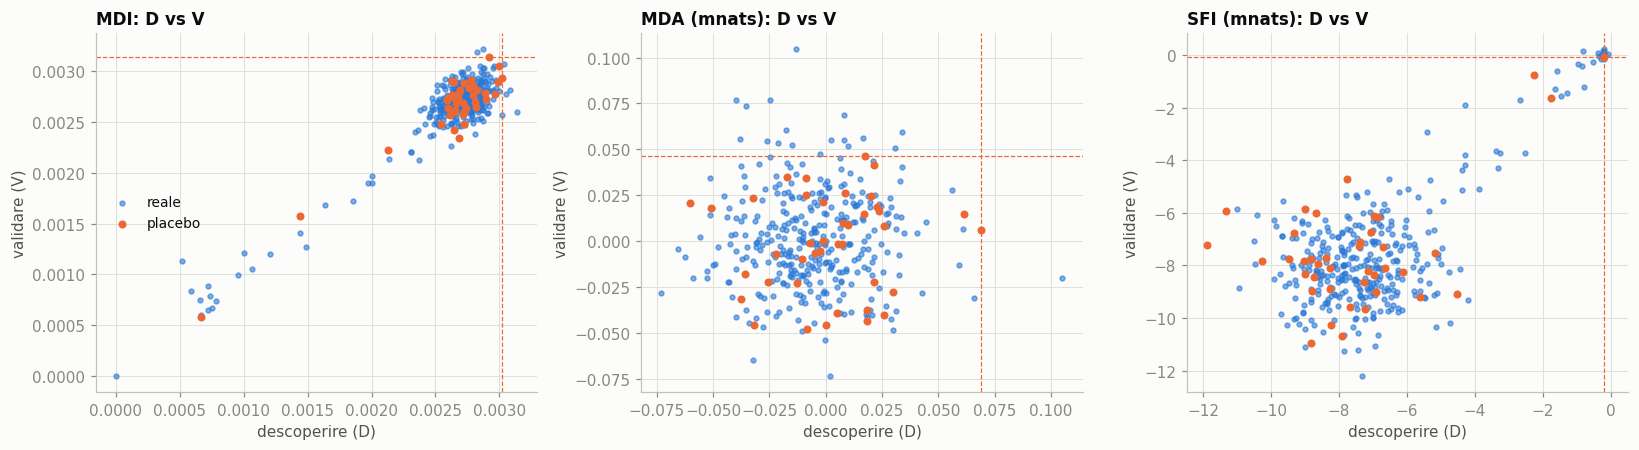

In [17]:
DISC = np.flatnonzero(EV["t0"] < DISC_END); VAL = np.flatnonzero(EV["t0"] >= DISC_END)
FOLDS_D = purged_kfold(t0n, t1n, idx=DISC); FOLDS_V = purged_kfold(t0n, t1n, idx=VAL)
def halves():
    return {"D": (mdi(XR, FEATS, idx=DISC), mda(XR, FEATS, FOLDS_D), sfi(XR, FEATS, FOLDS_D)),
            "V": (mdi(XR, FEATS, idx=VAL), mda(XR, FEATS, FOLDS_V), sfi(XR, FEATS, FOLDS_V))}
t = time.time()
HALF = cached("halves", halves)
print(f"({time.time() - t:.0f} s)")
TD, THD = summarize(*HALF["D"], REAL, PLAC); TV, THV = summarize(*HALF["V"], REAL, PLAC)
STAB = pd.DataFrame({m: {"Spearman D vs V (reale)": spearmanr(TD.loc[REAL, m], TV.loc[REAL, m])[0],
                         "peste placebo în D": int(TD.loc[REAL, f"{m.split()[0]} > placebo"].sum()), "peste placebo în V": int(TV.loc[REAL, f"{m.split()[0]} > placebo"].sum()),
                         "peste placebo în ambele": int((TD.loc[REAL, f"{m.split()[0]} > placebo"] & TV.loc[REAL, f"{m.split()[0]} > placebo"]).sum())}
                     for m in ("MDI", "MDA (mnats)", "SFI (mnats)")})
print("Stabilitatea importanței între perioada de descoperire (D, iul 2025 – feb 2026) și cea de validare (V, mar – oct 2026):")
display(STAB.round(3))
MDI_PERM = cached("mdi_perm", lambda: mdi(XR, FEATS, yy=np.random.default_rng(SEED + 99).permutation(y)))
print(f"Control: MDI calculat cu etichete amestecate aleator are corelația Spearman {spearmanr(MDI.loc[REAL, 'mean'].fillna(0), MDI_PERM.loc[REAL, 'mean'].fillna(0))[0]:.3f} "
      f"cu MDI-ul calculat pe etichetele reale. "
      f"AUC-ul SFI are corelația D vs V {spearmanr(TD.loc[REAL, 'SFI AUC'], TV.loc[REAL, 'SFI AUC'])[0]:.3f}.")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, m in zip(axes, ("MDI", "MDA (mnats)", "SFI (mnats)")):
    ax.scatter(TD.loc[REAL, m], TV.loc[REAL, m], s=10, color=C["blue"], alpha=.6, label="reale")
    ax.scatter(TD.loc[PLAC, m], TV.loc[PLAC, m], s=18, color=C["orange"], label="placebo")
    ax.axhline(THV[m], color=C["orange"], lw=.8, ls="--"); ax.axvline(THD[m], color=C["orange"], lw=.8, ls="--")
    ax.set_xlabel("descoperire (D)"); ax.set_ylabel("validare (V)"); ax.set_title(f"{m}: D vs V")
axes[0].legend(); fig.tight_layout(); plt.show()

**Interpretare.**

* **Niciun feature nu trece pragul placebo în ambele perioade**, cu nicio metodă.
* **MDI pare stabil** (Spearman D vs V 0,51), dar controlul arată de ce: MDI calculat cu **etichete amestecate** are corelația 0,47 cu MDI-ul real. Ordinea MDI e dată deci de forma feature-urilor (câte valori distincte au, cum sunt distribuite), nu de etichete. Este exact slăbiciunea MDI in-sample.
* **Log loss-ul SFI** are o stabilitate aparentă (0,28) din același motiv. Feature-urile binare sau rare supra-învață mai puțin, așa că primesc un log loss mai bun. AUC-ul SFI, care nu depinde de calibrare, are corelația D vs V **−0,11**.
* **MDA**, singura metodă out-of-sample care vede toate feature-urile împreună, are corelația D vs V 0,04.

## 9. Testul decisiv: selecția din trecut, aplicată pe viitor

**Selecția:** primele 15 feature-uri alese **doar** din perioada D (după numărul de metode trecute, apoi rangul MDA + SFI).

**Testul:** walk-forward lunar pe V. Pentru fiecare lună, modelul e antrenat pe toate evenimentele a căror etichetă s-a încheiat cu > 1 zi înainte de începutul lunii. Seturile comparate:

* toate feature-urile;
* componentele PCA, cu rotația refăcută lunar doar pe trecut;
* top 15 din D;
* doar `side`;
* doar placebo;
* 25 de seturi de câte 15 feature-uri alese la întâmplare.

**Măsurile:**

* câștigul de log loss și AUC;
* valoarea economică: randamentul brut al jumătății de evenimente cu probabilitatea cea mai mare, minus randamentul tuturor evenimentelor, cu interval de încredere prin bootstrap pe zile.

Ultimul tabel arată randamentul primarei pe chintile ale celor mai importante feature-uri, în fiecare perioadă. Rețeta din notebook-urile anterioare: un filtru are valoare doar dacă avantajul primarei variază cu feature-ul.

In [18]:
def select_top(T, k):
    # Ranking from the discovery period only: methods passed first, then MDA, then SFI.
    r = T.loc[REAL].drop(index="side").copy()
    r["score"] = r["rang MDA"] + r["rang SFI"]
    return r.sort_values(["metode trecute", "score"], ascending=[False, True]).index[:k].tolist()
K_TOP = 15
TOPD = select_top(TD, K_TOP)
print(f"Top {K_TOP} selectate DOAR din perioada de descoperire:", ", ".join(TOPD))
months = pd.date_range(DISC_END, DATA_END, freq="MS", tz=UTC)

def _wf_job(args):
    a, b, k = args
    te = np.flatnonzero((EV["t0"] >= a) & (EV["t0"] < b)).astype(int)
    tr = np.flatnonzero(t1n < (a - EMBARGO).value)
    if k == "componente PCA (rotație refăcută lunar)":
        Z = XR[[c for c in REAL if c != "side"]].to_numpy()
        ev_, V_ = np.linalg.eigh(np.cov(Z[tr], rowvar=False)); o_ = np.argsort(ev_)[::-1]; ev_, V_ = ev_[o_], V_[:, o_]
        V_ = V_[:, :int(np.searchsorted(np.cumsum(ev_) / ev_.sum(), 0.95) + 1)]
        A = np.column_stack([Z @ V_, XR["side"].to_numpy()]).astype(np.float32)
    else:
        A = XR[SETS[k]].to_numpy(np.float32)
    rf = make_rf(N_TREES_SMALL, SEED, n_jobs=1).fit(A[tr], y[tr], sample_weight=wgt[tr])
    return k, te, rf.predict_proba(A[te])[:, 1]
def walk_forward(cols_sets):
    """Monthly refit: train on all events whose label ends > 1 day before the month starts, predict the month."""
    P = {k: np.full(n_ev, np.nan) for k in cols_sets}
    for k, te, p in pmap(_wf_job, [(a, b, k) for a, b in zip(months[:-1], months[1:]) for k in cols_sets]):
        P[k][te] = p
    return P
N_RAND = 6 if QUICK else 25
rng = np.random.default_rng(SEED + 7)
pool = [c for c in REAL if c != "side"]
SETS = {"toate feature-urile": REAL, "componente PCA (rotație refăcută lunar)": REAL, f"top {K_TOP} din D": TOPD + ["side"], "doar side": ["side"], "placebo": PLAC + ["side"]}
for i in range(N_RAND):
    SETS[f"aleator {i:02d}"] = list(rng.choice(pool, K_TOP, replace=False)) + ["side"]
t = time.time()
WF = cached("walk_forward", lambda: walk_forward(SETS))
print(f"({time.time() - t:.0f} s)")
g = EV["gross"].to_numpy()
def wf_eval(p):
    m = np.isfinite(p); yy, pp, ww, gg = y[m], p[m], wgt[m], g[m]
    keep_ = pp >= np.median(pp)
    return {"câștig log loss (mnats)": 1e3 * (prior_ll(yy, ww) - wll(yy, pp, ww)), "AUC": roc_auc_score(yy, pp, sample_weight=ww),
            "brut toate (bps)": 1e4 * gg.mean(), "brut jumătatea de sus (bps)": 1e4 * gg[keep_].mean(), "brut jumătatea de jos (bps)": 1e4 * gg[~keep_].mean(),
            "diferență sus − toate (bps)": 1e4 * (gg[keep_].mean() - gg.mean())}
WFT = pd.DataFrame({k: wf_eval(p) for k, p in WF.items()}).T
rnd = WFT[WFT.index.str.startswith("aleator")]
summary = WFT.loc[["toate feature-urile", "componente PCA (rotație refăcută lunar)", f"top {K_TOP} din D", "doar side", "placebo"]].copy()
summary.loc[f"aleator {K_TOP} (medie din {N_RAND})"] = rnd.mean()
summary.loc[f"aleator {K_TOP} (percentila 90)"] = rnd.quantile(.9)
print(f"Walk-forward lunar pe perioada de validare (mar – oct 2026, {np.isfinite(WF['toate feature-urile']).sum():,} evenimente), toate în afara eșantionului:")
display(summary.round(3))
pct = {c: 100 * np.mean(rnd[c].to_numpy() < WFT.loc[f"top {K_TOP} din D", c]) for c in ["câștig log loss (mnats)", "AUC", "diferență sus − toate (bps)"]}
print(f"Percentila setului top {K_TOP} printre seturile aleatoare de aceeași mărime: " + ", ".join(f"{k}: {v:.0f}" for k, v in pct.items()))

# Bootstrap by day: gross of the upper half of the forecasts minus all trades in the same months
def boot_uplift(pp, reps=2000):
    m = np.isfinite(pp)
    dd = EV.loc[m, "t0"].dt.floor("D").to_numpy(); ud = np.unique(dd); di_ = np.searchsorted(ud, dd)
    keep_ = pp[m] >= np.median(pp[m]); gg = g[m]
    sa, na = np.bincount(di_, gg, len(ud)), np.bincount(di_, minlength=len(ud)).astype(float)
    sb, nb = np.bincount(di_, gg * keep_, len(ud)), np.bincount(di_, keep_.astype(float), len(ud))
    rr = np.random.default_rng(SEED + 11); bt = []
    for _ in range(reps):
        w_ = np.bincount(rr.integers(0, len(ud), len(ud)), minlength=len(ud)); bt.append((w_ @ sb) / (w_ @ nb) - (w_ @ sa) / (w_ @ na))
    return 1e4 * (gg[keep_].mean() - gg.mean()), 1e4 * np.percentile(bt, 2.5), 1e4 * np.percentile(bt, 97.5)
for k in ("toate feature-urile", "componente PCA (rotație refăcută lunar)", f"top {K_TOP} din D"):
    d_, lo_, hi_ = boot_uplift(WF[k])
    print(f"{k}: jumătatea de sus minus toate = {d_:+.2f} bps, IC 95% bootstrap pe zile [{lo_:+.2f}, {hi_:+.2f}] bps.")

Top 15 selectate DOAR din perioada de descoperire: ev_rv_240m_over_h2, ev_min_since_prev_event, ticker_base_volume_24h_btc, jump_trade_15m_grid1s, max_spread_bps_1s, std_basis_mid_index_bps_2m, o_settle_est_index_bps_p2, gap_ask12_bps, trade_size_p90_30s_usdt, trade_size_p90_2m_btc, ticker_range_log, opp_liq_notional_short_15m_usdt, own_notional_bid_50bps_usdt, run_length_trades, trade_size_p90_30s_btc
(0 s)


Walk-forward lunar pe perioada de validare (mar – oct 2026, 12,087 evenimente), toate în afara eșantionului:


,câștig log loss (mnats),AUC,brut toate (bps),brut jumătatea de sus (bps),brut jumătatea de jos (bps),diferență sus − toate (bps)
toate feature-urile,-0.301,0.506,-0.963,-1.192,-0.734,-0.229
componente PCA (rotație refăcută lunar),0.341,0.514,-0.963,-0.887,-1.039,0.076
top 15 din D,-2.495,0.496,-0.963,-1.481,-0.446,-0.517
doar side,-0.122,0.489,-0.963,-1.540,-0.336,-0.576
placebo,-1.099,0.494,-0.963,-0.913,-1.013,0.050
aleator 15 (medie din 25),-1.006,0.505,-0.963,-0.987,-0.940,-0.023
aleator 15 (percentila 90),-0.158,0.513,-0.963,-0.727,-0.593,0.236


Percentila setului top 15 printre seturile aleatoare de aceeași mărime: câștig log loss (mnats): 0, AUC: 4, diferență sus − toate (bps): 0
toate feature-urile: jumătatea de sus minus toate = -0.23 bps, IC 95% bootstrap pe zile [-0.77, +0.34] bps.


componente PCA (rotație refăcută lunar): jumătatea de sus minus toate = +0.08 bps, IC 95% bootstrap pe zile [-0.52, +0.62] bps.
top 15 din D: jumătatea de sus minus toate = -0.52 bps, IC 95% bootstrap pe zile [-1.08, +0.03] bps.


In [19]:
TOP_ALL = TAB.loc[REAL].drop(index="side").sort_values(["metode trecute", "MDA (mnats)"], ascending=False).head(8).index.tolist()
rows = []
for c in TOP_ALL:
    for per, idx in (("D", DISC), ("V", VAL)):
        q = pd.qcut(XR[c].to_numpy()[idx], 5, labels=False, duplicates="drop")
        gr = pd.Series(g[idx]).groupby(q).mean() * 1e4
        rows.append({"feature": c, "perioada": per, **{f"Q{int(k) + 1}": v for k, v in gr.items()}, "Q5 − Q1": gr.iloc[-1] - gr.iloc[0]})
QT = pd.DataFrame(rows).set_index(["feature", "perioada"])
print("Randamentul brut mediu al strategiei primare (bps) pe chintile ale feature-urilor cu cea mai mare importanță (Q1 = valori mici):")
display(QT.round(2))

Randamentul brut mediu al strategiei primare (bps) pe chintile ale feature-urilor cu cea mai mare importanță (Q1 = valori mici):


Q1    Q2    Q3    Q4    Q5  Q5 − Q1
feature                 perioada                                       
markout_1s_qw_bps_2m    D        -1.37 -0.75 -0.63 -1.14 -1.91    -0.54
                        V        -0.55 -0.34 -1.48 -0.85 -1.59    -1.04
o_liq_imbalance_30s     D        -0.86 -1.38   NaN   NaN   NaN    -0.52
                        V        -0.48 -1.36   NaN   NaN   NaN    -0.87
mean_trade_size_5s_btc  D        -0.98 -2.64 -0.59 -1.30 -0.28     0.70
                        V        -0.76 -0.05 -1.50 -1.17 -1.33    -0.57
o_funding_x_oi_level_rz D        -2.09 -1.25 -0.44 -1.39 -0.64     1.45
                        V        -2.50 -0.95 -0.61 -0.02 -0.74     1.76
trade_size_p90_2m_usdt  D        -0.40 -1.61 -1.34 -0.86 -1.60    -1.20
                        V         0.04 -0.94 -0.87 -1.29 -1.76    -1.79
own_cost_buy_0p1btc_bps D         0.15 -1.83 -2.19 -0.11 -1.82    -1.97
                        V        -0.98 -1.55 -0.93 -1.12 -0.23     0.74
o_mlofi_norm_l5_30s     D        -1.01 -0.30 -2.68 -1.53 -0.28     0.73
                        V        -2.11 -0.68 -0.24 -0.27 -1.51     0.61
o_qi_25bps              D        -1.75 -0.77 -1.50 -0.50 -1.28     0.46
                        V        -2.43 -1.08 -1.20  0.16 -0.22     2.21

## 1. Verificarea datasetului

Fiecare lună e citită integral. Verific invarianții barei: timp monoton, `bar_id` unic, `eval_time ≤ decision_time`, L ≤ O, C ≤ H, VWAP în [L, H], |tfi_ratio| ≤ 1, identitatea tfi_ratio = tfi/V, spread ≥ 0, |qi_1| ≤ 1 și randamentul egal cu log(C/C₋₁). Apoi măsor, pentru fiecare dintre cele 666 de coloane, valorile lipsă, cele infinite și coloanele constante, lună cu lună.0

In [20]:
FINAL = TAB.loc[REAL].drop(index="side").copy()
FINAL["D: metode"] = TD.loc[FINAL.index, "metode trecute"]; FINAL["V: metode"] = TV.loc[FINAL.index, "metode trecute"]
FINAL["blocuri peste placebo"] = PAR_TAB.loc[FINAL.index, "blocuri peste placebo"]
FINAL["stivuit > placebo"] = PAR_TAB.loc[FINAL.index, "stivuit > placebo"]
FINAL["MDA V (mnats)"] = TV.loc[FINAL.index, "MDA (mnats)"]; FINAL["SFI V (mnats)"] = TV.loc[FINAL.index, "SFI (mnats)"]
def verdict(T_full, T_d, T_v, par_tab, idx):
    full_, d_, v_ = T_full.loc[idx, "metode trecute"], T_d.loc[idx, "metode trecute"], T_v.loc[idx, "metode trecute"]
    blocks = par_tab.loc[idx, "blocuri peste placebo"] if par_tab is not None else 0
    return pd.Series(np.select([(full_ >= 2) & (d_ >= 1) & (v_ >= 1) & (blocks >= 2), (full_ >= 1) & ((d_ >= 1) | (v_ >= 1))],
                               ["robust", "candidat"], "zgomot"), index=idx)
FINAL["verdict"] = verdict(TAB, TD, TV, PAR_TAB, FINAL.index)
# The same rule applied to the placebo features (leave-one-out thresholds) gives the rate at which pure noise earns each verdict.
PAR_PL = pd.DataFrame({"blocuri peste placebo": pd.DataFrame({b: pd.Series({p_: (d.at[p_, "mean"] > d.loc[[q for q in PLAC if q != p_], "mean"].max()) and
                                                                                 (d.at[p_, "mean"] - 2 * d.at[p_, "se"] > 0) for p_ in PLAC})
                                                              for b, d in PAR.items()}).sum(1)})
v_pl = verdict(TAB, TD, TV, PAR_PL, PLAC)
VER = pd.DataFrame({"feature-uri reale": FINAL["verdict"].value_counts(), "procent reale": 100 * FINAL["verdict"].value_counts(normalize=True),
                    "procent placebo": 100 * v_pl.value_counts(normalize=True)}).reindex(["robust", "candidat", "zgomot"]).fillna(0)
VER["așteptat din întâmplare (reale)"] = VER["procent placebo"] / 100 * len(FINAL)
display(VER.round(1))
cols_show = ["MDI", "MDA (mnats)", "MDA se", "SFI (mnats)", "SFI AUC", "metode trecute", "D: metode", "V: metode", "blocuri peste placebo", "stivuit > placebo", "verdict"]
display(FINAL.sort_values(["verdict", "metode trecute", "MDA (mnats)"], ascending=[True, False, False]).head(30)[cols_show].round(4))

,feature-uri reale,procent reale,procent placebo,așteptat din întâmplare (reale)
robust,0.0,0.0,0.0,0.0
candidat,3.0,0.9,2.5,8.5
zgomot,338.0,99.1,97.5,332.5


,MDI,MDA (mnats),MDA se,SFI (mnats),SFI AUC,metode trecute,D: metode,V: metode,blocuri peste placebo,stivuit > placebo,verdict
mean_trade_size_5s_btc,0.0027,0.0302,0.0095,-3.9826,0.5017,1,0,1,0,False,candidat
trade_size_p90_2m_usdt,0.0028,0.0269,0.0108,-2.6334,0.5174,1,0,1,0,False,candidat
ev_o_ret_60m_over_h,0.0031,0.0021,0.0113,-5.0460,0.4986,1,0,1,0,False,candidat
markout_1s_qw_bps_2m,0.0028,0.0384,0.0142,-3.4560,0.5030,1,0,0,0,False,zgomot
o_liq_imbalance_30s,0.0009,0.0346,0.0084,-0.2463,0.5029,1,0,0,0,False,zgomot
o_funding_x_oi_level_rz,0.0027,0.0291,0.0124,-4.1177,0.5007,1,0,0,0,False,zgomot
own_cost_buy_0p1btc_bps,0.0028,0.0262,0.0096,-3.3685,0.5079,1,0,0,0,False,zgomot
o_mlofi_norm_l5_30s,0.0026,0.0260,0.0097,-3.9528,0.5031,1,0,0,0,False,zgomot
o_qi_25bps,0.0031,0.0222,0.0247,-3.5807,0.5032,1,0,0,0,False,zgomot
day_of_week_sin,0.0032,0.0186,0.0175,-4.4933,0.5048,1,0,0,0,False,zgomot


## Concluzii

**1. Datasetul este corect, dar are capcane de care trebuie ținut cont.**

* Invarianții barelor și identitățile feature-urilor trec în toate lunile. Nu există valori infinite.
* Ferestrele stricte lungi lipsesc des: 24h la 87% din bare, 4h la 40%, 1h la 17%. Folosește variante tolerante la goluri, calculate din bare.
* Cartea de ordine e degradată în martie–mai 2026.
* **75% din barele de volum se închid în mijlocul unui sweep.** Feature-urile de flux și de carte pe 5 s „prezic” bara următoare doar pentru că restul aceluiași ordin agresiv cade în bara următoare. Efectul dispare după 0,1–1 s, deci orice etichetă pe bare de volum are nevoie de latență la intrare.

**2. Pentru meta-labeling pe evenimente CUSUM cu triple barrier, niciun feature nu aduce semnal care să se distingă de zgomot.**

* Cele trei metode cerute (MDI, MDA, SFI), cu toate măsurile anti-mascare și anti-scurgere, dau sub nivelul de șansă feature-uri peste placebo. Niciun feature nu trece două metode.
* PCA + τ ponderat nu confirmă: 0,04 și −0,09, în interiorul distribuției cu etichete amestecate.
* Rangurile nu se repetă între regimuri (0,02), între cele două jumătăți ale perioadei (0,04) sau între paralel și stivuit.
* Selecția făcută în trecut este mai slabă decât una aleatoare în viitor.
* Feature-urile reale nu bat feature-urile placebo decalate în timp.

**3. Ce *pare* important, dar nu e semnal.** Topul MDI (`day_of_week_sin`, `ev_o_ret_60m_over_h`, `o_qi_25bps`, `jump_trade_5s`) se explică prin forma feature-urilor: MDI pe etichete amestecate are corelația 0,47 cu MDI-ul real. Topul MDA (`markout_1s_qw_bps_2m`, `o_liq_imbalance_30s`, `mean_trade_size_5s_btc`, `o_funding_x_oi_level_rz`, `trade_size_p90_2m_usdt`) nu se repetă în nicio jumătate de perioadă.

**4. De ce.** Cu bariere simetrice, meta-label-ul unei primare care urmează direcția CUSUM este direcția mișcării din următoarele ~27 de minute. Notebook-urile anterioare au arătat că direcția pe acest orizont e aproape imposibil de prezis cu aceste date. Singurul semnal direcțional cunoscut (imbalanța cărții) e de sub 1 bps și se consumă în primele secunde. Volatilitatea se poate prezice, dar cu bariere simetrice ea crește la fel câștigurile și pierderile.

**5. Ce merită testat pe date de după 2026-10-31** (ipoteze, nu rezultate):

* `o_funding_x_oi_level_rz` și `o_qi_25bps` ca filtre: au diferențe Q5 − Q1 cu același semn în ambele perioade;
* modelul pe componente PCA refăcute lunar: AUC 0,514 în walk-forward, peste percentila 90 a seturilor aleatoare (0,513), dar fără valoare economică încă;
* o primară cu avantaj brut pozitiv (de exemplu reversie după CUSUM cu execuție mai bună), pentru că meta-labeling-ul nu poate repara o primară fără avantaj;
* bariere asimetrice, singurul caz în care feature-urile de volatilitate pot conta.

In [21]:
assert source_fingerprint() == FINGERPRINT_START, "Datele sursă s-au modificat în timpul rulării."
print(f"Datele sursă nu au fost modificate. Durata rulării: {(time.time() - T0) / 60:.1f} min; memorie maximă {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB; seed {SEED}.")

Datele sursă nu au fost modificate. Durata rulării: 0.8 min; memorie maximă 1.6 GB; seed 20261109.
